In [6]:
# -*- coding: utf-8 -*-
# ╔══════════════════════════════════════════════════════════════════════════════╗
# ║  UAV Multi-Agent TD3-ARC  ·  Colab-Ready Single File                       ║
# ╠══════════════════════════════════════════════════════════════════════════════╣
# ║  COLAB CELL GUIDE — copy each marked block into its own Colab cell         ║
# ║  ─────────────────────────────────────────────────────────────────────────  ║
# ║  CELL 1 │ INSTALL        — pip install (run once per session)              ║
# ║  CELL 2 │ IMPORTS        — all imports + helpers                           ║
# ║  CELL 3 │ CONFIG         — tweak episodes, paths, hyperparams here        ║
# ║  CELL 4 │ ENV + PHYSICS  — SDF, wind, environment class                   ║
# ║  CELL 5 │ NETWORKS       — LSTM actor/critic                               ║
# ║  CELL 6 │ AGENT          — TD3 agent                                       ║
# ║  CELL 7 │ BUFFER + HER   — replay buffer + hindsight experience replay     ║
# ║  CELL 8 │ TRAINER        — MultiUAVTrainer class                           ║
# ║  CELL 9 │ VISUALISATION  — matplotlib PNG/GIF + Three.js HTML viewer       ║
# ║  ─────────────────────────────────────────────────────────────────────────  ║
# ║  RUN CELLS:                                                                 ║
# ║  ▶ TRAIN          → run CELL 1-9, then: trainer = run_training()          ║
# ║  ▶ TEST ONLY      → run CELL 1-9, then: run_test()                        ║
# ║  ▶ VISUALISE ONLY → run CELL 1-9, then: run_visualise()                   ║
# ╚══════════════════════════════════════════════════════════════════════════════╝

# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
# CELL 1 │ INSTALL  (run once per Colab session)
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
# Paste into a Colab cell and run:
#   !pip install -q torch numpy matplotlib pillow

# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
# CELL 2 │ IMPORTS
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

import os, sys, time, csv, copy, random, math, json
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from collections import deque

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from mpl_toolkits.mplot3d import Axes3D          # noqa: F401
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
from matplotlib.colors import LinearSegmentedColormap

def _in_colab():
    try:
        import google.colab; return True
    except ImportError:
        return False

def _show_image(path):
    if _in_colab():
        from IPython.display import Image, display
        display(Image(path))
    else:
        print(f"  [saved] {path}")

def _show_html(path):
    if _in_colab():
        from IPython.display import IFrame, display
        display(IFrame(src=path, width="100%", height="700px"))
    else:
        print(f"  [saved] {path}")

print("✅ CELL 2 done — imports loaded")


# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
# CELL 3 │ CONFIG  ← edit your run settings here
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

# ── Run settings ──────────────────────────────────────────────────────────────
NUM_EPISODES      = 100       # total training episodes this session
N_ENVS            = 5         # parallel UAVs (lower to 2 if GPU OOM)
SEED              = 42
RESUME_PATH       = "/kaggle/working/models_uav/arc_multi_best.pt"        # path to .pt checkpoint, or "" for fresh training
SAVE_DIR          = "models_uav"
VISUALIZE_EVERY_N = 100       # save PNG+HTML viewer every N episodes (0 = off)
MAKE_GIF          = True
GIF_FPS           = 18
GIF_TAIL          = 30
TEST_EPISODES     = 10

# ── Stage selector ────────────────────────────────────────────────────────────
# Set which curriculum stage to START training at (0, 1, or 2).
# Stage 0 = easy (4 obstacles, near-goal starts)  ← always start here from scratch
# Stage 1 = medium (15 obstacles)
# Stage 2 = hard (23 obstacles + decorative swirls)
# The trainer auto-advances when success rate thresholds are hit.
# If resuming a checkpoint already trained past stage 0, set this to match.
START_STAGE = 0

# ── Environment ───────────────────────────────────────────────────────────────
ARC3D_CONFIG = {
    "ENV_BOUNDS":  (0.0, 20.0, 0.0, 20.0, 0.0, 15.0),
    "START":       np.array([1.0,  1.0,  1.0]),
    "GOAL":        np.array([18.5, 18.5, 12.0]),
    "GOAL_RADIUS": 0.80,

    # Training start zones expand with curriculum stage.
    # Stage 0: start NEAR the goal (within ~6 m) so random policy reaches it early.
    # Stage 1/2: progressively wider until the full arena is sampled.
    # This is the single most important fix for 0% success — the critic can't
    # learn anything if a random policy never accidentally reaches the goal.
    "TRAIN_START_BOUNDS_BY_STAGE": {
        0: {"cx": 18.5, "cy": 18.5, "cz": 12.0, "r": 6.0},   # sphere around goal, r=6m
        1: {"cx": 18.5, "cy": 18.5, "cz": 12.0, "r": 12.0},  # sphere r=12m
        2: None,                                                 # full arena random
    },

    "CURRICULUM": {
        # Stage 0 — easy: 4 obstacles, clear path exists
        0: {
            "obstacles": [
                {"type": "sphere",   "center": np.array([ 5.0,  5.0,  4.0]), "radius": 1.2},
                {"type": "sphere",   "center": np.array([10.0, 10.0,  7.0]), "radius": 1.0},
                {"type": "box",      "center": np.array([ 7.0,  3.0,  5.0]),
                                     "half":   np.array([0.8,  0.8,  1.5])},
                {"type": "sphere",   "center": np.array([14.0, 14.0,  9.0]), "radius": 1.0},
            ],
        },
        # Stage 1 — medium: denser, cylinders, narrow gate slab
        1: {
            "obstacles": [
                {"type": "sphere",   "center": np.array([ 4.0,  4.0,  3.0]), "radius": 1.2},
                {"type": "sphere",   "center": np.array([ 9.0,  9.0,  6.0]), "radius": 1.1},
                {"type": "sphere",   "center": np.array([14.0, 14.0,  9.0]), "radius": 1.0},
                {"type": "sphere",   "center": np.array([ 6.0, 13.0,  5.0]), "radius": 0.9},
                {"type": "sphere",   "center": np.array([13.0,  6.0,  9.0]), "radius": 0.9},
                {"type": "sphere",   "center": np.array([11.0, 17.0,  7.0]), "radius": 0.8},
                {"type": "sphere",   "center": np.array([17.0,  9.0,  5.0]), "radius": 0.8},
                {"type": "box",      "center": np.array([ 7.0,  3.0,  5.0]),
                                     "half":   np.array([0.8,  0.8,  2.0])},
                {"type": "box",      "center": np.array([ 3.0, 10.0,  3.0]),
                                     "half":   np.array([1.0,  0.5,  2.5])},
                {"type": "box",      "center": np.array([15.0,  5.0,  4.0]),
                                     "half":   np.array([0.6,  1.2,  3.0])},
                {"type": "box",      "center": np.array([ 9.0, 15.0,  2.0]),
                                     "half":   np.array([2.0,  0.4,  4.0])},
                {"type": "cylinder", "center": np.array([11.0,  5.0,  0.0]),
                                     "radius": 0.7, "height": 8.0},
                {"type": "cylinder", "center": np.array([ 5.0, 16.0,  0.0]),
                                     "radius": 0.7, "height": 8.0},
                {"type": "cylinder", "center": np.array([16.0, 13.0,  0.0]),
                                     "radius": 0.6, "height": 6.0},
                {"type": "box",      "center": np.array([10.0,  8.0,  5.5]),   # narrow gate
                                     "half":   np.array([3.5,  0.25,  1.2])},
            ],
        },
        # Stage 2 — hard: 10 spheres, 6 boxes, 5 cylinders + 3 decorative swirl zones
        # (swirl zones are VISUAL ONLY — no physics effect on the UAV)
        2: {
            "obstacles": [
                {"type": "sphere",   "center": np.array([ 4.0,  4.0,  3.0]), "radius": 1.2},
                {"type": "sphere",   "center": np.array([ 9.0,  9.0,  6.0]), "radius": 1.1},
                {"type": "sphere",   "center": np.array([14.0, 14.0,  9.0]), "radius": 1.0},
                {"type": "sphere",   "center": np.array([ 6.0, 13.0,  5.0]), "radius": 0.9},
                {"type": "sphere",   "center": np.array([13.0,  6.0,  9.0]), "radius": 0.9},
                {"type": "sphere",   "center": np.array([17.0,  4.0, 11.0]), "radius": 0.8},
                {"type": "sphere",   "center": np.array([ 3.0, 17.0, 11.0]), "radius": 0.8},
                {"type": "sphere",   "center": np.array([11.0, 17.0,  7.0]), "radius": 0.85},
                {"type": "sphere",   "center": np.array([17.0,  9.0,  5.0]), "radius": 0.85},
                {"type": "sphere",   "center": np.array([ 7.0, 11.0, 10.0]), "radius": 0.75},
                {"type": "box",      "center": np.array([ 7.0,  3.0,  5.0]),
                                     "half":   np.array([0.8,  0.8,  2.0])},
                {"type": "box",      "center": np.array([ 3.0, 10.0,  3.0]),
                                     "half":   np.array([1.0,  0.5,  2.5])},
                {"type": "box",      "center": np.array([16.0, 11.0,  6.0]),
                                     "half":   np.array([1.5,  0.5,  3.0])},
                {"type": "box",      "center": np.array([10.0, 17.0,  4.0]),
                                     "half":   np.array([0.5,  1.5,  3.0])},
                {"type": "box",      "center": np.array([15.0,  5.0,  4.0]),
                                     "half":   np.array([0.6,  1.2,  3.0])},
                {"type": "box",      "center": np.array([ 9.0, 15.0,  2.0]),
                                     "half":   np.array([2.0,  0.4,  4.0])},
                {"type": "box",      "center": np.array([10.0,  8.0,  5.0]),   # gate slab 1
                                     "half":   np.array([3.0,  0.3,  1.5])},
                {"type": "box",      "center": np.array([10.0, 12.0,  5.0]),   # gate slab 2
                                     "half":   np.array([3.0,  0.3,  1.5])},
                {"type": "cylinder", "center": np.array([11.0,  5.0,  0.0]),
                                     "radius": 0.7, "height": 9.0},
                {"type": "cylinder", "center": np.array([ 5.0, 16.0,  0.0]),
                                     "radius": 0.7, "height": 9.0},
                {"type": "cylinder", "center": np.array([16.0, 16.0,  0.0]),
                                     "radius": 0.9, "height": 7.0},
                {"type": "cylinder", "center": np.array([ 2.0,  8.0,  0.0]),
                                     "radius": 0.6, "height": 11.0},
                {"type": "cylinder", "center": np.array([13.0,  2.0,  0.0]),
                                     "radius": 0.6, "height": 8.0},
                # ── decorative swirl zones (visual only, no physics) ──────────
                # "swirl" type is ignored by the env SDF pipeline; only the
                # HTML viewer renders them as animated green wireframe spheres.
                {"type": "swirl",    "center": np.array([ 7.0,  7.0,  6.0]), "radius": 2.5},
                {"type": "swirl",    "center": np.array([13.0, 12.0,  8.0]), "radius": 2.2},
                {"type": "swirl",    "center": np.array([10.0,  5.0, 10.0]), "radius": 1.8},
            ],
        },
    },
    "OBSTACLE_SPEED_SCALE": 0.06,
}

# ── Network architecture ───────────────────────────────────────────────────────
NETWORK3D_CONFIG = {
    "lstm_hidden_size":  256,
    "lstm_num_layers":   2,
    "actor_hidden_size": 512,
    "critic_hidden_size":512,
    "history_length":    10,
    "dropout":           0.05,
}

TRAIN3D_CONFIG = {
    "num_episodes":           NUM_EPISODES,
    "batch_size":              256,
    "memory_capacity":       100_000,  # smaller fills faster → more diverse early batches
    "learning_rate":           1e-4,
    "gamma":                   0.98,   # shorter horizon: easier early credit assignment
    "tau":                     0.005,
    "exploration_noise":       0.35,
    # CRITICAL FIX: decay applied per EPISODE not per step
    # 0.992^200 ≈ 0.20, so noise goes 0.35 → 0.08 over ~200 episodes
    "noise_decay":             0.992,
    "noise_floor":             0.08,
    "warmup_steps":            500,    # stage-0 episodes are short, fills fast
    "policy_delay":            2,
    "target_noise":            0.1,
    "target_noise_clip":       0.3,
    "curriculum_thresholds":   [0.50, 0.65],
    "curriculum_window":       20,     # rolling window for success rate check
    "her_k":                   6,
    "n_envs":                  N_ENVS,
    "updates_per_episode":     4,
    "start_stage":             START_STAGE,
}

MODEL3D_CONFIG = {
    "save_dir":      SAVE_DIR,
    "save_interval":  100,
    "log_csv":       os.path.join(SAVE_DIR, "training_log.csv"),
}

LOG_FIELDS = [
    "episode","stage","reward_mean","reward_min","reward_max",
    "success_rate","collision_rate","energy_out_rate",
    "steps_mean","path_length_mean","smoothness_mean",
    "energy_remaining_mean","avg_clearance_mean",
    "critic1_loss","critic2_loss","actor_loss",
    "avg_q1","target_q","noise","buffer_size",
]

print("✅ CELL 3 done — config loaded")


# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
# CELL 4 │ ENV + PHYSICS
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

# ── SDF primitives ─────────────────────────────────────────────────────────────

def _sdf_sphere(p, c, r):
    return np.linalg.norm(p - c) - r

def _sdf_box(p, c, h):
    q = np.abs(p - c) - h
    return np.linalg.norm(np.maximum(q, 0.0)) + min(float(np.max(q)), 0.0)

def _sdf_cylinder(p, c, r, height):
    dx = np.linalg.norm(p[:2] - c[:2]) - r
    dz = abs(p[2] - (c[2] + height * 0.5)) - height * 0.5
    return float(np.linalg.norm(np.maximum([dx, dz], 0.0)) + min(max(dx, dz), 0.0))

# "swirl" is visual-only → treated as fully empty space (infinite SDF)
_SOLID_TYPES = {"sphere", "box", "cylinder"}

def obs_sdf(p, obs):
    t = obs["type"]
    if t == "sphere":   return _sdf_sphere(p, obs["center"], obs["radius"])
    if t == "box":      return _sdf_box(p, obs["center"], obs["half"])
    if t == "cylinder": return _sdf_cylinder(p, obs["center"], obs["radius"], obs["height"])
    return 9999.0  # swirl / unknown → no collision

def obs_sdf_gradient(p, obs, eps=0.01):
    g = np.zeros(3)
    for i in range(3):
        d = np.zeros(3); d[i] = eps
        g[i] = (obs_sdf(p + d, obs) - obs_sdf(p - d, obs)) / (2 * eps)
    n = np.linalg.norm(g)
    return g / (n + 1e-8)

def min_clearance(p, obstacles):
    vals = [obs_sdf(p, o) for o in obstacles if o["type"] in _SOLID_TYPES]
    return max(0.0, min(vals)) if vals else 9999.0

def nearest_obstacle(p, obstacles):
    best_d, best_o = 9999.0, None
    for o in obstacles:
        if o["type"] not in _SOLID_TYPES: continue
        d = obs_sdf(p, o)
        if d < best_d: best_d, best_o = d, o
    return best_d, best_o

def in_collision(p, obstacles, margin=0.05):
    return any(obs_sdf(p, o) < margin
               for o in obstacles if o["type"] in _SOLID_TYPES)

def has_los(a, b, obstacles, n=12):
    return not any(in_collision(a + t*(b-a), obstacles, 0.05)
                   for t in np.linspace(0, 1, n))

def angle_wrap(a):
    return (a + np.pi) % (2 * np.pi) - np.pi


# ── Wind model ─────────────────────────────────────────────────────────────────

class WindModel:
    def __init__(self, rng, sigma=0.08, tau=2.0, dt=0.1):
        self.sigma=sigma; self.tau=tau; self.dt=dt; self.rng=rng
        self.wind=np.zeros(3)
    def reset(self): self.wind=self.rng.normal(0, self.sigma*0.5, 3)
    def step(self):
        alpha=np.exp(-self.dt/self.tau)
        self.wind=alpha*self.wind+(1-alpha)*self.rng.normal(0, self.sigma, 3)
        return self.wind.copy()


# ── Environment ────────────────────────────────────────────────────────────────

class UAVEnvironmentPro:
    """
    18-D observation · 3-D continuous action · curriculum difficulty.

    Reward improvements vs first version:
      • K_PROGRESS 12 → 15   : stronger goal-pull
      • R_GOAL 500 → 600      : unambiguous terminal reward
      • R_COLLISION -200 → -150 : less catastrophic, agent keeps trying
      • dist_shaping bonus    : extra +K_DIST_BONUS when within 3 m of goal
    """

    OBS_DIM = 18
    ACT_DIM = 3

    MAX_STEPS       = 1200
    STEP_SIZE       = 0.15
    MAX_DELTA_YAW   = np.pi / 4
    MAX_DELTA_PITCH = np.pi / 5
    MIN_SPEED       = 0.30
    MAX_SPEED       = 1.00
    COLLISION_M     = 0.07

    ENERGY_MAX      = 1.0
    ENERGY_PER_STEP = 0.0008
    ENERGY_SPEED_K  = 0.0005
    ENERGY_TURN_K   = 0.0003

    # ── reward weights ────────────────────────────────────────────────────────
    # DESIGN RULE: staying still must always produce NEGATIVE reward.
    # The only way to earn positive reward is to make progress toward the goal.
    # Every other term (align, LOS, smoothness) is removed or made zero-based.
    #
    # Per-step budget (stationary UAV, no obstacles):
    #   R_STEP=-0.05, progress=0, align_bonus=0, energy_pen≈-0.008
    #   Total ≈ -0.058/step  → always negative → agent MUST move
    #
    # Per-step budget (moving straight at goal, 0.3m/step):
    #   R_STEP=-0.05, progress≈+0.3*K_PROGRESS=+1.2
    #   Total ≈ +1.15/step  → strongly positive → agent rewarded for moving

    R_STEP          = -0.05    # strong enough that staying still is always losing
    K_PROGRESS      =  4.0     # reward per metre of progress (clipped at ±0.5m)
    K_CLEARANCE     =  0.3     # obstacle clearance penalty (only when too close)
    D_SAFE          =  0.8
    K_BOUNDARY      =  0.1
    BOUND_SAFE      =  0.6
    K_ENERGY        =  0.05    # mild energy penalty
    R_GOAL          =  100.0   # terminal success reward
    R_COLLISION     = -50.0    # terminal collision penalty
    R_ENERGY_OUT    = -30.0
    K_DIST_BONUS    =  2.0     # extra pull in final 3 m (helps convergence)

    # Removed: K_ALIGN, K_LOS, K_ACTION, K_SMOOTH — these create standing-still attractors

    DIST_NORM       =  26.0

    def __init__(self, seed=None, stage=0, train_mode=True):
        self.rng        = np.random.default_rng(seed)
        self.wind_mdl   = WindModel(self.rng)
        self.stage      = stage
        self.train_mode = train_mode
        self.bounds     = ARC3D_CONFIG["ENV_BOUNDS"]
        self._fixed_start = ARC3D_CONFIG["START"].copy()
        self.goal       = ARC3D_CONFIG["GOAL"].copy()
        self.goal_radius= ARC3D_CONFIG.get("GOAL_RADIUS", 0.80)
        self._load_stage(stage)
        self.reset()

    def set_stage(self, s): self.stage=s; self._load_stage(s)

    def _load_stage(self, stage):
        s = ARC3D_CONFIG["CURRICULUM"][stage]
        self._base_obstacles = copy.deepcopy(s["obstacles"])

    def reset(self):
        self.obstacles = copy.deepcopy(self._base_obstacles)

        if self.train_mode:
            tsb = ARC3D_CONFIG["TRAIN_START_BOUNDS_BY_STAGE"].get(self.stage)
            placed = False
            for _ in range(80):
                if tsb is None:
                    # Stage 2: full arena random
                    cand = np.array([
                        self.rng.uniform(0.5, self.bounds[1]-0.5),
                        self.rng.uniform(0.5, self.bounds[3]-0.5),
                        self.rng.uniform(0.5, self.bounds[5]-0.5),
                    ])
                else:
                    # Sample inside sphere around goal (rejection sampling)
                    cx,cy,cz,r = tsb["cx"],tsb["cy"],tsb["cz"],tsb["r"]
                    u = self.rng.uniform(-1,1,3)
                    u = u / (np.linalg.norm(u)+1e-9)
                    rad = r * self.rng.uniform(0.2, 1.0)**(1/3)  # uniform in sphere volume
                    cand = np.clip(
                        np.array([cx,cy,cz]) + u*rad,
                        [0.4,0.4,0.4],
                        [self.bounds[1]-0.4, self.bounds[3]-0.4, self.bounds[5]-0.4])
                if not in_collision(cand, self.obstacles, 0.5):
                    self.start = cand; placed = True; break
            if not placed:
                self.start = self._fixed_start.copy()
        else:
            self.start = self._fixed_start.copy()

        self.pos=self.start.copy(); self.vel=np.zeros(3)
        to_goal=self.goal-self.pos
        self.yaw   = float(np.arctan2(to_goal[1], to_goal[0]))
        self.pitch = float(np.arctan2(to_goal[2], np.linalg.norm(to_goal[:2])+1e-9))
        self._prev_yaw=self.yaw; self._prev_pitch=self.pitch
        self.step_n=0; self.energy=self.ENERGY_MAX
        self._prev_dist=float(np.linalg.norm(self.pos-self.goal))
        self._prev_action=np.zeros(3)
        self.path=[self.pos.copy()]; self.curvatures=[]
        self.wind_mdl.reset()
        self._wind=self.wind_mdl.step()
        return self._obs()

    def step(self, action):
        self._wind=self.wind_mdl.step()

        delta_yaw   = float(action[0])*self.MAX_DELTA_YAW
        delta_pitch = float(action[1])*self.MAX_DELTA_PITCH
        raw_speed   = float(action[2])
        speed = self.MIN_SPEED+(raw_speed+1)/2*(self.MAX_SPEED-self.MIN_SPEED)

        self._prev_yaw=self.yaw; self._prev_pitch=self.pitch
        self.yaw   = angle_wrap(self.yaw+delta_yaw)
        self.pitch = float(np.clip(self.pitch+delta_pitch, -np.pi/2, np.pi/2))

        cx=np.cos(self.pitch)*np.cos(self.yaw)
        cy=np.cos(self.pitch)*np.sin(self.yaw)
        cz=np.sin(self.pitch)
        move = np.array([cx,cy,cz])*self.STEP_SIZE*speed + self._wind*0.05

        xlo,xhi,ylo,yhi,zlo,zhi=self.bounds
        prev_pos=self.pos.copy()
        new_pos=np.clip(self.pos+move,
                        [xlo+0.01,ylo+0.01,zlo+0.01],
                        [xhi-0.01,yhi-0.01,zhi-0.01])

        hit=False
        for t in np.linspace(0,1,5):
            if in_collision(prev_pos+t*(new_pos-prev_pos), self.obstacles, self.COLLISION_M):
                hit=True; break

        self.vel=(new_pos-self.pos) if not hit else np.zeros(3)
        if not hit: self.pos=new_pos
        self.step_n+=1; self.path.append(self.pos.copy())

        energy_cost=(self.ENERGY_PER_STEP
                     +self.ENERGY_SPEED_K*speed**2
                     +self.ENERGY_TURN_K*(abs(delta_yaw)+abs(delta_pitch)))
        self.energy=max(0.0, self.energy-energy_cost)

        dist_now  = float(np.linalg.norm(self.pos-self.goal))
        # Progress: metres closed this step, clipped to prevent spike exploitation
        progress  = float(np.clip(self._prev_dist - dist_now, -0.5, 0.5))

        # Obstacle clearance penalty — only fires when genuinely too close
        clr = min_clearance(self.pos, self.obstacles)
        clamped = max(clr, 0.05)
        clearance_pen = (float(np.clip(-self.K_CLEARANCE*(1/clamped - 1/self.D_SAFE), -3., 0.))
                         if clamped < self.D_SAFE else 0.)

        # Boundary penalty — only fires near walls
        margins = [self.pos[0]-xlo, xhi-self.pos[0],
                   self.pos[1]-ylo, yhi-self.pos[1],
                   self.pos[2]-zlo, zhi-self.pos[2]]
        boundary_pen = -self.K_BOUNDARY * max(0., (self.BOUND_SAFE - min(margins)) / self.BOUND_SAFE)

        # Energy penalty — mild, only discourages extreme manoeuvres
        energy_pen = -self.K_ENERGY * energy_cost * 10

        # Close-range bonus — extra pull in final 3 m
        dist_bonus = self.K_DIST_BONUS * (1.0 - dist_now / 3.0) if dist_now < 3.0 else 0.0

        # TOTAL: R_STEP is negative enough that only positive progress saves the episode
        reward = (self.R_STEP
                  + self.K_PROGRESS * progress
                  + clearance_pen
                  + boundary_pen
                  + energy_pen
                  + dist_bonus)
        self._prev_dist = dist_now; self._prev_action = action.copy()

        if len(self.path)>=3:
            a_=self.path[-3]; b_=self.path[-2]; c_=self.pos
            ab=b_-a_; bc=c_-b_
            la=np.linalg.norm(ab); lb=np.linalg.norm(bc)
            if la>1e-6 and lb>1e-6:
                self.curvatures.append(float(
                    np.arccos(np.clip(np.dot(ab,bc)/(la*lb),-1,1))))

        done=False; success=collision=energy_out=False
        if   dist_now<=self.goal_radius:
            reward+=self.R_GOAL;  done=True; success=True
        elif hit:
            reward+=self.R_COLLISION; done=True; collision=True
        elif self.energy<=0.:
            reward+=self.R_ENERGY_OUT; done=True; energy_out=True
        elif self.step_n>=self.MAX_STEPS:
            done=True

        info={"success":success,"collision":collision,"energy_out":energy_out,
              "energy":self.energy,"clearance":clr,"dist_to_goal":dist_now,
              "smoothness":float(np.mean(self.curvatures)) if self.curvatures else 0.,
              "pos":self.pos.copy(),"goal":self.goal.copy()}
        return self._obs(), float(reward), done, info

    def _obs(self):
        to_goal   = self.goal-self.pos
        dist_goal = float(np.linalg.norm(to_goal))+1e-9; unit=to_goal/dist_goal
        dist_n    = float(np.clip(dist_goal/self.DIST_NORM,0,1))
        vel_n     = np.clip(self.vel/0.25,-1,1)
        clr       = min_clearance(self.pos,self.obstacles)
        clr_n     = float(np.clip(clr/5.0,0,1))
        goal_yaw   = float(np.arctan2(to_goal[1],to_goal[0]))
        goal_pitch = float(np.arctan2(to_goal[2],np.linalg.norm(to_goal[:2])+1e-9))
        yaw_err    = angle_wrap(goal_yaw-self.yaw)/np.pi
        pitch_err  = angle_wrap(goal_pitch-self.pitch)/(np.pi/2)
        yaw_rate   = float(np.clip(angle_wrap(self.yaw-self._prev_yaw)/(np.pi/4),-1,1))
        pitch_rate = float(np.clip(angle_wrap(self.pitch-self._prev_pitch)/(np.pi/5),-1,1))
        d_near,near_obs=nearest_obstacle(self.pos,self.obstacles)
        grad=(obs_sdf_gradient(self.pos,near_obs)
              if near_obs is not None and d_near<3.0 else np.zeros(3))
        wind_obs=np.clip(self._wind[:2]/0.12,-1,1)
        return np.array([unit[0],unit[1],unit[2],dist_n,
                         vel_n[0],vel_n[1],vel_n[2],clr_n,
                         float(np.clip(yaw_err,-1,1)),float(np.clip(pitch_err,-1,1)),
                         yaw_rate,pitch_rate,grad[0],grad[1],grad[2],
                         wind_obs[0],wind_obs[1],float(self.energy)],dtype=np.float32)

    def path_array(self): return np.array(self.path)

print("✅ CELL 4 done — environment ready")


# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
# CELL 5 │ NETWORKS
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

class LSTMEncoder(nn.Module):
    def __init__(self, input_size, hidden_size, num_layers=2, dropout=0.05):
        super().__init__()
        self.lstm=nn.LSTM(input_size,hidden_size,num_layers,batch_first=True,
                          dropout=dropout if num_layers>1 else 0.)
        self.norm=nn.LayerNorm(hidden_size)
    def forward(self,x,hidden=None):
        out,hidden=self.lstm(x,hidden); return self.norm(out[:,-1,:]),hidden

class ActorNetwork(nn.Module):
    def __init__(self,obs_dim,action_dim,lstm_h,lstm_layers,actor_h,dropout):
        super().__init__()
        self.lstm=LSTMEncoder(obs_dim,lstm_h,lstm_layers,dropout)
        self.net=nn.Sequential(nn.Linear(lstm_h,actor_h),nn.ReLU(),
                               nn.Linear(actor_h,actor_h),nn.ReLU(),
                               nn.Linear(actor_h,action_dim),nn.Tanh())
    def forward(self,history,hidden=None):
        z,hidden=self.lstm(history,hidden); return self.net(z),hidden

class CriticNetwork(nn.Module):
    def __init__(self,obs_dim,action_dim,lstm_h,lstm_layers,critic_h,dropout):
        super().__init__()
        self.lstm=LSTMEncoder(obs_dim,lstm_h,lstm_layers,dropout)
        self.net=nn.Sequential(nn.Linear(lstm_h+action_dim,critic_h),nn.ReLU(),
                               nn.Linear(critic_h,critic_h),nn.ReLU(),
                               nn.Linear(critic_h,1))
    def forward(self,history,action,hidden=None):
        z,hidden=self.lstm(history,hidden)
        return self.net(torch.cat([z,action],dim=-1)),hidden

print("✅ CELL 5 done — networks defined")


# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
# CELL 6 │ TD3 AGENT
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

class TD3Agent:
    def __init__(self,obs_dim,action_dim,config,device):
        self.device=device; self.obs_dim=obs_dim; self.action_dim=action_dim
        lh=config["lstm_hidden_size"]; ll=config["lstm_num_layers"]
        ah=config["actor_hidden_size"]; ch=config["critic_hidden_size"]
        dr=config.get("dropout",0.05);  lr=config["learning_rate"]
        mk_a=lambda:ActorNetwork(obs_dim,action_dim,lh,ll,ah,dr).to(device)
        mk_c=lambda:CriticNetwork(obs_dim,action_dim,lh,ll,ch,dr).to(device)
        self.actor=mk_a(); self.actor_target=mk_a()
        self.actor_target.load_state_dict(self.actor.state_dict())
        self.critic1=mk_c(); self.critic2=mk_c()
        self.critic1_target=mk_c(); self.critic2_target=mk_c()
        self.critic1_target.load_state_dict(self.critic1.state_dict())
        self.critic2_target.load_state_dict(self.critic2.state_dict())
        self.actor_opt  =torch.optim.Adam(self.actor.parameters(),   lr=lr*0.5)
        self.critic1_opt=torch.optim.Adam(self.critic1.parameters(), lr=lr)
        self.critic2_opt=torch.optim.Adam(self.critic2.parameters(), lr=lr)
        self.policy_delay     =config.get("policy_delay",2)
        self.target_noise     =config.get("target_noise",0.10)
        self.target_noise_clip=config.get("target_noise_clip",0.3)
        self._update_count=0

    def select_actions_batch(self,histories_batch,noise_scale=0.0):
        with torch.no_grad():
            actions,_=self.actor(histories_batch)
            if noise_scale>0:
                actions=(actions+torch.randn_like(actions)*noise_scale).clamp(-1,1)
        return actions.cpu().numpy()

    def select_action(self,history,hidden=None,noise_scale=0.0):
        if history.dim()==2: history=history.unsqueeze(0)
        with torch.no_grad():
            action,new_hidden=self.actor(history,hidden)
            if noise_scale>0:
                action=(action+torch.randn_like(action)*noise_scale).clamp(-1,1)
        if new_hidden is not None:
            new_hidden=(new_hidden[0].detach(),new_hidden[1].detach())
        return action.cpu().numpy()[0],new_hidden

    def update(self,batch,gamma,tau):
        self._update_count+=1
        h=batch["history"]; a=batch["action"]; r=batch["reward"]
        nh=batch["next_history"]; done=batch["done"]
        w=batch.get("weights",torch.ones_like(r))
        with torch.no_grad():
            noise=(torch.randn_like(a)*self.target_noise
                   ).clamp(-self.target_noise_clip,self.target_noise_clip)
            na,_=self.actor_target(nh); na=(na+noise).clamp(-1,1)
            q1n,_=self.critic1_target(nh,na); q2n,_=self.critic2_target(nh,na)
            target_q=r+(1.-done)*gamma*torch.min(q1n,q2n)
        q1,_=self.critic1(h,a); td1=(q1-target_q).abs().detach()
        loss1=(w*F.mse_loss(q1,target_q,reduction="none")).mean()
        self.critic1_opt.zero_grad(); loss1.backward()
        nn.utils.clip_grad_norm_(self.critic1.parameters(),5.); self.critic1_opt.step()
        q2,_=self.critic2(h,a); td2=(q2-target_q).abs().detach()
        loss2=(w*F.mse_loss(q2,target_q,reduction="none")).mean()
        self.critic2_opt.zero_grad(); loss2.backward()
        nn.utils.clip_grad_norm_(self.critic2.parameters(),5.); self.critic2_opt.step()
        actor_loss=None
        if self._update_count%self.policy_delay==0:
            pa,_=self.actor(h); q1fa,_=self.critic1(h,pa)
            actor_loss=-q1fa.mean()
            self.actor_opt.zero_grad(); actor_loss.backward()
            nn.utils.clip_grad_norm_(self.actor.parameters(),1.); self.actor_opt.step()
            for tgt,src in [(self.actor_target,self.actor),
                            (self.critic1_target,self.critic1),
                            (self.critic2_target,self.critic2)]:
                for tp,op in zip(tgt.parameters(),src.parameters()):
                    tp.data.copy_(tau*op.data+(1-tau)*tp.data)
        per_td=((td1+td2)/2.).squeeze(1).cpu().numpy()
        return {"critic1_loss":loss1.item(),"critic2_loss":loss2.item(),
                "actor_loss":actor_loss.item() if actor_loss else float("nan"),
                "avg_q1":q1.mean().item(),"target_q":target_q.mean().item(),
                "per_sample_td":per_td}

    def save(self,path):
        torch.save({"actor":self.actor.state_dict(),
                    "actor_target":self.actor_target.state_dict(),
                    "critic1":self.critic1.state_dict(),
                    "critic2":self.critic2.state_dict(),
                    "critic1_target":self.critic1_target.state_dict(),
                    "critic2_target":self.critic2_target.state_dict(),
                    "actor_opt":self.actor_opt.state_dict(),
                    "critic1_opt":self.critic1_opt.state_dict(),
                    "critic2_opt":self.critic2_opt.state_dict(),
                    "update_count":self._update_count},path)

    def load(self,path):
        ck=torch.load(path,map_location=self.device)
        self.actor.load_state_dict(ck["actor"])
        self.actor_target.load_state_dict(ck["actor_target"])
        self.critic1.load_state_dict(ck["critic1"])
        self.critic2.load_state_dict(ck["critic2"])
        self.critic1_target.load_state_dict(ck["critic1_target"])
        self.critic2_target.load_state_dict(ck["critic2_target"])
        self.actor_opt.load_state_dict(ck["actor_opt"])
        self.critic1_opt.load_state_dict(ck["critic1_opt"])
        self.critic2_opt.load_state_dict(ck["critic2_opt"])
        self._update_count=ck.get("update_count",0)

print("✅ CELL 6 done — TD3 agent defined")


# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
# CELL 7 │ REPLAY BUFFER + HER
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

class PrioritisedReplayBuffer:
    def __init__(self,capacity,obs_dim,history_length,device,alpha=0.6,beta_start=0.4):
        self.capacity=capacity; self.device=device
        self.alpha=alpha; self.beta=beta_start; self.beta_end=1.0
        self._tree=np.zeros(2*capacity+1); self._data=[None]*capacity
        self._ptr=0; self._size=0; self._max_pri=1.0

    def _update_tree(self,idx,priority):
        ti=idx+self.capacity; self._tree[ti]=priority
        parent=(ti-1)//2
        while parent>=0:
            self._tree[parent]=self._tree[2*parent+1]+self._tree[2*parent+2]
            if parent==0: break
            parent=(parent-1)//2

    def _sample_idx(self,v):
        idx=0
        while idx<self.capacity-1:
            l,r=2*idx+1,2*idx+2
            idx=l if v<=self._tree[l] else (r, v.__isub__(self._tree[l]))[0]
            if idx==r: v-=self._tree[l]
        return idx-self.capacity

    def push(self,history,action,reward,next_history,done):
        self._data[self._ptr]={"history":history,"action":action,"reward":reward,
                                "next_history":next_history,"done":done}
        self._update_tree(self._ptr,self._max_pri**self.alpha)
        self._ptr=(self._ptr+1)%self.capacity
        self._size=min(self._size+1,self.capacity)

    def sample(self,batch_size):
        total=max(self._tree[0],1e-8); seg=total/batch_size
        idxs,exps,probs=[],[],[]
        for i in range(batch_size):
            v=np.random.uniform(seg*i,seg*(i+1))
            idx=self._sample_idx_safe(np.clip(v,0,total-1e-8))
            if self._data[idx] is None: idx=self._ptr%max(self._size,1)
            idxs.append(idx); exps.append(self._data[idx])
            p=max(self._tree[idx+self.capacity],1e-10)/total; probs.append(p)
        probs=np.array(probs); weights=(self._size*probs)**(-self.beta)
        weights/=weights.max()
        batch=self._collate(exps)
        batch["weights"]=torch.FloatTensor(weights).unsqueeze(1).to(self.device)
        batch["indices"]=idxs; return batch

    def _sample_idx_safe(self,v):
        idx=0
        while idx<self.capacity-1:
            l,r=2*idx+1,2*idx+2
            if v<=self._tree[l]: idx=l
            else: v-=self._tree[l]; idx=r
        return idx-self.capacity

    def update_priorities(self,indices,td_errors):
        for idx,err in zip(indices,td_errors):
            pri=(abs(float(err))+1e-6)**self.alpha
            self._max_pri=max(self._max_pri,pri); self._update_tree(idx,pri)

    def anneal_beta(self,frac): self.beta=self.beta+frac*(self.beta_end-self.beta)

    def _collate(self,exps):
        h=np.stack([e["history"] for e in exps]); a=np.stack([e["action"] for e in exps])
        r=np.array([e["reward"] for e in exps]); nh=np.stack([e["next_history"] for e in exps])
        d=np.array([e["done"] for e in exps])
        return {"history":torch.FloatTensor(h).to(self.device),
                "action": torch.FloatTensor(a).to(self.device),
                "reward": torch.FloatTensor(r).unsqueeze(1).to(self.device),
                "next_history":torch.FloatTensor(nh).to(self.device),
                "done":   torch.FloatTensor(d).unsqueeze(1).to(self.device)}

    def __len__(self): return self._size


class ObservationHistory:
    def __init__(self,history_length,obs_dim):
        self.history_length=history_length; self._buf=deque(maxlen=history_length)
    def reset(self,obs):
        self._buf.clear()
        for _ in range(self.history_length): self._buf.append(obs.copy())
    def append(self,obs): self._buf.append(obs.copy())
    def get(self): return np.array(list(self._buf))
    def get_tensor(self,device): return torch.FloatTensor(self.get()).unsqueeze(0).to(device)


def compute_her_reward(pos, virtual_goal, goal_radius=0.80):
    return 100.0 if np.linalg.norm(pos - virtual_goal) <= goal_radius else -0.05

def _patch_obs_for_goal(obs, pos, vgoal, current_yaw, current_pitch, dist_norm=26.0):
    """
    Recompute all goal-dependent fields in obs for a virtual goal.
    obs layout: [unit(0:3), dist_n(3), vel(4:7), clr(7), yaw_err(8),
                 pitch_err(9), yaw_rate(10), pitch_rate(11), grad(12:15),
                 wind(15:17), energy(17)]
    Fields 0-3, 8, 9 depend on goal; everything else stays unchanged.
    """
    o = obs.copy()
    tg = vgoal - pos
    d  = np.linalg.norm(tg) + 1e-9
    u  = tg / d
    o[0], o[1], o[2] = u[0], u[1], u[2]
    o[3] = float(np.clip(d / dist_norm, 0, 1))
    goal_yaw   = float(np.arctan2(tg[1], tg[0]))
    goal_pitch = float(np.arctan2(tg[2], np.linalg.norm(tg[:2]) + 1e-9))
    o[8] = float(np.clip(angle_wrap(goal_yaw   - current_yaw)   / np.pi,        -1, 1))
    o[9] = float(np.clip(angle_wrap(goal_pitch - current_pitch) / (np.pi/2),    -1, 1))
    return o

def add_episode_her(replay, episode_transitions, k=8, goal_radius=0.80):
    n = len(episode_transitions)
    if n < 2: return
    for t_idx, t in enumerate(episode_transitions):
        future_idxs = np.random.randint(t_idx, n, size=min(k, n-t_idx))
        for fi in future_idxs:
            vg = episode_transitions[fi]["next_pos"].copy()
            h_new  = t["history"].copy()
            nh_new = t["next_history"].copy()
            if h_new.ndim == 2:
                h_new[-1]  = _patch_obs_for_goal(h_new[-1],  t["pos"],      vg,
                                                  t["yaw"],  t["pitch"])
                nh_new[-1] = _patch_obs_for_goal(nh_new[-1], t["next_pos"], vg,
                                                  t["next_yaw"], t["next_pitch"])
            hr = compute_her_reward(t["next_pos"], vg, goal_radius)
            replay.push(h_new, t["action"], hr, nh_new, 1. if hr > 0 else 0.)

print("✅ CELL 7 done — buffer + HER ready")


# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
# CELL 8 │ MULTI-UAV TRAINER
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

class MultiUAVTrainer:
    """
    N_ENVS UAVs share one TD3 agent + one replay buffer.
    Training   → random start per episode (diverse experience)
    Evaluation → fixed canonical start (reproducible test)
    """

    def __init__(self,device=None,resume_path=None,n_envs=None,seed=42):
        self.device=device or torch.device("cuda" if torch.cuda.is_available() else "cpu")
        print(f"\n{'='*65}")
        print(f"  Multi-UAV TD3-ARC  |  device={self.device}")
        if torch.cuda.is_available(): print(f"  GPU: {torch.cuda.get_device_name(0)}")
        print(f"{'='*65}")
        self.n_envs   = n_envs or TRAIN3D_CONFIG["n_envs"]
        self.stage    = 0
        self.obs_dim  = UAVEnvironmentPro.OBS_DIM
        self.act_dim  = UAVEnvironmentPro.ACT_DIM
        hist_len      = NETWORK3D_CONFIG["history_length"]
        start_stage   = TRAIN3D_CONFIG.get("start_stage", 0)
        self.stage    = start_stage

        self.envs     = [UAVEnvironmentPro(seed=seed+i,  stage=start_stage, train_mode=True)  for i in range(self.n_envs)]
        self.test_env = UAVEnvironmentPro(seed=seed+999, stage=start_stage, train_mode=False)

        agent_cfg={**NETWORK3D_CONFIG,**TRAIN3D_CONFIG}
        self.agent=TD3Agent(self.obs_dim,self.act_dim,agent_cfg,self.device)
        self.replay=PrioritisedReplayBuffer(
            capacity=TRAIN3D_CONFIG["memory_capacity"],
            obs_dim=self.obs_dim,history_length=hist_len,
            device=self.device,alpha=0.6,beta_start=0.4)

        os.makedirs(MODEL3D_CONFIG["save_dir"],exist_ok=True)
        self.ep_stats=[]; self._best_succ=0.0
        self._curr_thresholds=TRAIN3D_CONFIG["curriculum_thresholds"]
        self._curr_window    =TRAIN3D_CONFIG.get("curriculum_window", 20)
        self._her_k=TRAIN3D_CONFIG.get("her_k", 6)

        resume=resume_path or RESUME_PATH
        if resume and os.path.exists(resume):
            self.agent.load(resume); print(f"  Resumed from: {resume}")
        else:
            print("  Starting from scratch")

        with open(MODEL3D_CONFIG["log_csv"],"w",newline="") as f:
            csv.DictWriter(f,fieldnames=LOG_FIELDS).writeheader()
        print(f"  n_envs={self.n_envs}  obs={self.obs_dim}  act={self.act_dim}  start_stage={start_stage}\n")

    def _advance_stage(self):
        self.stage+=1
        for env in self.envs: env.set_stage(self.stage)
        self.test_env.set_stage(self.stage)
        print(f"\n  *** CURRICULUM ADVANCE → Stage {self.stage} ***\n")

    def _test_episode(self):
        obs=self.test_env.reset()
        oh=ObservationHistory(NETWORK3D_CONFIG["history_length"],self.obs_dim)
        oh.reset(obs); hidden=None; done=False
        while not done:
            ht=oh.get_tensor(self.device)
            action,hidden=self.agent.select_action(ht,hidden,noise_scale=0.)
            obs,_,done,info=self.test_env.step(action); oh.append(obs)
        return self.test_env.path_array(),info

    def train(self,num_episodes=None):
        num_ep     =num_episodes or TRAIN3D_CONFIG["num_episodes"]
        warmup     =TRAIN3D_CONFIG["warmup_steps"]
        batch_size =TRAIN3D_CONFIG["batch_size"]
        noise      =TRAIN3D_CONFIG["exploration_noise"]
        decay      =TRAIN3D_CONFIG["noise_decay"]
        noise_fl   =TRAIN3D_CONFIG["noise_floor"]
        goal_r     =self.envs[0].goal_radius
        hist_len   =NETWORK3D_CONFIG["history_length"]
        updates_ep =TRAIN3D_CONFIG["updates_per_episode"]

        print(f"  Training {num_ep} eps × {self.n_envs} UAVs  "
              f"(warmup={warmup}  noise={noise:.2f}→{noise_fl:.2f}  HER k={self._her_k})")
        print(f"  Stage-0 starts sampled within 6 m of goal — expands with curriculum.\n")

        obs_list   =[env.reset() for env in self.envs]
        oh_list    =[ObservationHistory(hist_len,self.obs_dim) for _ in self.envs]
        for i,obs in enumerate(obs_list): oh_list[i].reset(obs)
        # Per-env LSTM hidden state — carried across steps, reset on episode end
        hidden_list= [None]*self.n_envs
        ep_r_list  =[0.]*self.n_envs; ep_clr_list=[[] for _ in self.envs]
        ep_trans   =[[] for _ in self.envs]; ep_done=[False]*self.n_envs; ep_info=[{}]*self.n_envs
        log_r=[];log_succ=[];log_coll=[];log_eout=[]
        log_st=[];log_pl=[];log_sm=[];log_er=[];log_cl=[]
        all_succ=[]  # rolling success history for curriculum check
        lc1=lc2=lal=lq1=ltq=0.; ln=0
        global_ep=0; total_steps=0; t0=time.time(); log_ev=max(1,num_ep//40)

        while global_ep<num_ep:
            # Build per-env actions. During warmup use random; afterwards use actor.
            # We do it env-by-env so hidden states are carried correctly.
            actions_np = np.zeros((self.n_envs, self.act_dim), dtype=np.float32)
            if total_steps < warmup:
                actions_np = np.random.uniform(-1,1,(self.n_envs,self.act_dim)).astype(np.float32)
            else:
                for i in range(self.n_envs):
                    if ep_done[i]: continue
                    ht = oh_list[i].get_tensor(self.device)
                    act, hidden_list[i] = self.agent.select_action(
                        ht, hidden_list[i], noise_scale=noise)
                    actions_np[i] = act

            for i,(env,oh) in enumerate(zip(self.envs,oh_list)):
                if ep_done[i]: continue
                action   = actions_np[i]
                cur_pos  = env.pos.copy()
                cur_yaw  = env.yaw
                cur_pitch= env.pitch
                cur_hist = oh.get().copy()
                next_obs,reward,done,info=env.step(action)
                ep_r_list[i]+=reward; ep_clr_list[i].append(info["clearance"])
                oh.append(next_obs); next_hist=oh.get().copy()
                self.replay.push(cur_hist,action,reward,next_hist,float(done))
                ep_trans[i].append({
                    "history":cur_hist, "action":action.copy(),
                    "reward":reward, "next_history":next_hist,
                    "done":float(done), "pos":cur_pos, "next_pos":info["pos"],
                    "yaw":cur_yaw, "pitch":cur_pitch,
                    "next_yaw":env.yaw, "next_pitch":env.pitch,
                })
                if done: ep_done[i]=True; ep_info[i]=info

            total_steps+=self.n_envs

            for i in range(self.n_envs):
                if not ep_done[i]: continue
                info=ep_info[i]
                if not info.get("success",False) and len(ep_trans[i])>1:
                    add_episode_her(self.replay,ep_trans[i],self._her_k,goal_r)
                pa=self.envs[i].path_array()
                pl=float(np.sum(np.linalg.norm(np.diff(pa,axis=0),axis=1)))
                log_r.append(ep_r_list[i]); log_succ.append(int(info.get("success",False)))
                log_coll.append(int(info.get("collision",False)))
                log_eout.append(int(info.get("energy_out",False)))
                log_st.append(len(ep_trans[i])); log_pl.append(pl)
                log_sm.append(info.get("smoothness",0.)); log_er.append(info.get("energy",0.))
                log_cl.append(float(np.mean(ep_clr_list[i])) if ep_clr_list[i] else 0.)
                obs_new=self.envs[i].reset(); oh_list[i].reset(obs_new)
                hidden_list[i]=None  # reset LSTM hidden on new episode
                ep_r_list[i]=0.; ep_clr_list[i]=[]; ep_trans[i]=[]
                ep_done[i]=False; global_ep+=1
                if global_ep>=num_ep: break

            if len(self.replay)>=batch_size and total_steps>warmup:
                frac=min(global_ep/max(num_ep-1,1),1.)
                self.replay.anneal_beta(frac)
                for _ in range(updates_ep):
                    batch=self.replay.sample(batch_size)
                    losses=self.agent.update(batch,TRAIN3D_CONFIG["gamma"],TRAIN3D_CONFIG["tau"])
                    lc1+=losses["critic1_loss"]; lc2+=losses["critic2_loss"]
                    al=losses["actor_loss"]; lal+=al if not np.isnan(al) else 0.
                    lq1+=losses["avg_q1"]; ltq+=losses["target_q"]; ln+=1
                    self.replay.update_priorities(batch["indices"],losses["per_sample_td"])

            # Noise decay per EPISODE (not per step) — prevents hitting floor in ~36 eps
            # We apply it once per completed episode across any env
            new_eps_this_iter = sum(1 for d in ep_done if d)
            for _ in range(new_eps_this_iter):
                noise = max(noise * decay, noise_fl)

            if global_ep>0 and global_ep%log_ev==0 and log_r:
                div=max(ln,1)
                row={"episode":global_ep,"stage":self.stage,
                     "reward_mean":round(float(np.mean(log_r)),3),
                     "reward_min":round(float(np.min(log_r)),3),
                     "reward_max":round(float(np.max(log_r)),3),
                     "success_rate":round(float(np.mean(log_succ)),4),
                     "collision_rate":round(float(np.mean(log_coll)),4),
                     "energy_out_rate":round(float(np.mean(log_eout)),4),
                     "steps_mean":round(float(np.mean(log_st)),1),
                     "path_length_mean":round(float(np.mean(log_pl)),3),
                     "smoothness_mean":round(float(np.mean(log_sm)),4),
                     "energy_remaining_mean":round(float(np.mean(log_er)),4),
                     "avg_clearance_mean":round(float(np.mean(log_cl)),4),
                     "critic1_loss":round(lc1/div,5),"critic2_loss":round(lc2/div,5),
                     "actor_loss":round(lal/div,5),"avg_q1":round(lq1/div,4),
                     "target_q":round(ltq/div,4),"noise":round(noise,5),
                     "buffer_size":len(self.replay)}
                self.ep_stats.append(row)
                all_succ.extend(log_succ)  # running success history for curriculum
                with open(MODEL3D_CONFIG["log_csv"],"a",newline="") as f:
                    csv.DictWriter(f,fieldnames=LOG_FIELDS).writerow(row)
                el=(time.time()-t0)/60
                print(f"  ep {global_ep:5d}/{num_ep} | stg {self.stage} | "
                      f"r {row['reward_mean']:8.1f} | succ {row['success_rate']*100:5.1f}% | "
                      f"coll {row['collision_rate']*100:5.1f}% | "
                      f"CL {row['critic1_loss']:.4f} | AL {row['actor_loss']:.4f} | "
                      f"noise {noise:.4f} | {el:.1f}min")

                # Curriculum check: rolling window over recent episodes, checked every log interval
                if len(all_succ) >= self._curr_window:
                    rs = float(np.mean(all_succ[-self._curr_window:]))
                    ti = min(self.stage, len(self._curr_thresholds)-1)
                    if self.stage < 2 and rs >= self._curr_thresholds[ti]:
                        self._advance_stage()
                        all_succ = []  # reset window after stage advance

                rs=float(np.mean(all_succ[-self._curr_window:])) if len(all_succ)>=self._curr_window else 0.
                if rs>self._best_succ:
                    self._best_succ=rs
                    self.agent.save(os.path.join(MODEL3D_CONFIG["save_dir"],"arc_multi_best.pt"))

                if VISUALIZE_EVERY_N>0 and global_ep%VISUALIZE_EVERY_N==0:
                    traj,tinfo=self._test_episode()
                    png_p=os.path.join(MODEL3D_CONFIG["save_dir"],f"vis_ep{global_ep}.png")
                    fig=make_static_figure(traj,self.test_env.obstacles,
                                           ARC3D_CONFIG["START"],ARC3D_CONFIG["GOAL"],
                                           ARC3D_CONFIG["ENV_BOUNDS"],
                                           title=f"ep {global_ep}  succ={tinfo['success']}")
                    fig.savefig(png_p,dpi=130,facecolor="#"+VIS["BG"],bbox_inches="tight")
                    plt.close(fig); _show_image(png_p)
                    html_p=os.path.join(MODEL3D_CONFIG["save_dir"],f"viewer_ep{global_ep}.html")
                    make_interactive_viewer(traj,self.test_env.obstacles,
                                            ARC3D_CONFIG["START"],ARC3D_CONFIG["GOAL"],
                                            ARC3D_CONFIG["ENV_BOUNDS"],html_p,
                                            title=f"UAV Path — ep {global_ep}")
                    _show_html(html_p)

                log_r=[]; log_succ=[]; log_coll=[]; log_eout=[]
                log_st=[]; log_pl=[]; log_sm=[]; log_er=[]; log_cl=[]
                lc1=lc2=lal=lq1=ltq=0.; ln=0

            if global_ep>0 and global_ep%MODEL3D_CONFIG["save_interval"]==0:
                ckpt=os.path.join(MODEL3D_CONFIG["save_dir"],f"arc_multi_ep{global_ep}.pt")
                self.agent.save(ckpt)
                traj,info=self._test_episode()
                npy_p=os.path.join(MODEL3D_CONFIG["save_dir"],f"test_traj_ep{global_ep}.npy")
                np.save(npy_p,traj)
                print(f"  [ckpt ep={global_ep}] success={info['success']}  "
                      f"dist={info['dist_to_goal']:.2f}m  → {npy_p}")

        elapsed=time.time()-t0
        print(f"\n{'='*65}\n  Training done  ({elapsed/60:.1f} min)  "
              f"total_env_steps≈{total_steps:,}\n{'='*65}")
        final=os.path.join(MODEL3D_CONFIG["save_dir"],"arc_multi_final.pt")
        self.agent.save(final); print(f"  Final model → {final}")
        return self

    def test(self,model_path=None,n_episodes=10):
        mp=model_path or os.path.join(MODEL3D_CONFIG["save_dir"],"arc_multi_best.pt")
        if os.path.exists(mp): self.agent.load(mp); print(f"  Loaded: {mp}")
        print(f"\n  Testing {n_episodes} eps  fixed start→goal\n")
        succs=[]; pls=[]; steps_list=[]; last_traj=None; last_info={}
        for ep in range(n_episodes):
            traj,info=self._test_episode()
            pl=float(np.sum(np.linalg.norm(np.diff(traj,axis=0),axis=1)))
            succs.append(int(info["success"])); pls.append(pl)
            steps_list.append(self.test_env.step_n); last_traj=traj; last_info=info
            np.save(os.path.join(MODEL3D_CONFIG["save_dir"],f"test_ep{ep+1}.npy"),traj)
            print(f"  ep {ep+1:3d}: success={info['success']}  "
                  f"dist={info['dist_to_goal']:.2f}m  steps={self.test_env.step_n}  path={pl:.2f}m")
        print(f"\n  Success: {np.mean(succs)*100:.1f}%  "
              f"Avg path: {np.mean(pls):.2f}m  Avg steps: {np.mean(steps_list):.0f}")
        return last_traj, last_info

print("✅ CELL 8 done — trainer class ready")


# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
# CELL 9 │ VISUALISATION
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

VIS = dict(
    BG="0a1628", GRID="#1e3a5f",
    TRAJ_C1="#00e5ff", TRAJ_C2="#ffffff",
    SPH_RED="#ff3333", SPH_TEAL="#00bcd4",
    BOX="#5c35cc", CYL="#7b52ab",
    SWIRL="#00e676",
    START="#00e5ff", GOAL="#ffd600", UAV="#ff4444",
)

def _sphere_mesh(c,r,n=12):
    u=np.linspace(0,2*np.pi,n); v=np.linspace(0,np.pi,n)
    return (c[0]+r*np.outer(np.cos(u),np.sin(v)),
            c[1]+r*np.outer(np.sin(u),np.sin(v)),
            c[2]+r*np.outer(np.ones(n),np.cos(v)))

def _box_faces(c,h):
    cx,cy,cz=c; hx,hy,hz=h
    vt=[[cx-hx,cy-hy,cz-hz],[cx+hx,cy-hy,cz-hz],[cx+hx,cy+hy,cz-hz],[cx-hx,cy+hy,cz-hz],
        [cx-hx,cy-hy,cz+hz],[cx+hx,cy-hy,cz+hz],[cx+hx,cy+hy,cz+hz],[cx-hx,cy+hy,cz+hz]]
    return [[vt[0],vt[1],vt[2],vt[3]],[vt[4],vt[5],vt[6],vt[7]],
            [vt[0],vt[1],vt[5],vt[4]],[vt[2],vt[3],vt[7],vt[6]],
            [vt[0],vt[3],vt[7],vt[4]],[vt[1],vt[2],vt[6],vt[5]]]

def _cyl_mesh(c,r,h,n=16):
    th=np.linspace(0,2*np.pi,n); x=c[0]+r*np.cos(th); y=c[1]+r*np.sin(th)
    return (np.array([x,x]),np.array([y,y]),
            np.array([np.full(n,c[2]),np.full(n,c[2]+h)]))

def _setup_ax(ax,bounds):
    ax.set_facecolor("#"+VIS["BG"]); ax.figure.patch.set_facecolor("#"+VIS["BG"])
    xlo,xhi,ylo,yhi,zlo,zhi=bounds
    ax.set_xlim(xlo,xhi); ax.set_ylim(ylo,yhi); ax.set_zlim(zlo,zhi)
    for axis in [ax.xaxis,ax.yaxis,ax.zaxis]:
        axis.label.set_color("#4fc3f7"); axis.set_tick_params(colors="#4fc3f7",labelsize=7)
        axis.pane.fill=False; axis.pane.set_edgecolor(VIS["GRID"])
    ax.set_xlabel("X",color="#4fc3f7",fontsize=9)
    ax.set_ylabel("Y",color="#4fc3f7",fontsize=9)
    ax.set_zlabel("Z",color="#4fc3f7",fontsize=9)
    ax.grid(True,color=VIS["GRID"],linewidth=0.4,alpha=0.5)

def _draw_obstacles(ax,obstacles):
    for i,obs in enumerate(obstacles):
        t=obs["type"]; c=obs["center"]
        if t=="sphere":
            col=VIS["SPH_RED"] if i%2==0 else VIS["SPH_TEAL"]
            x,y,z=_sphere_mesh(c,obs["radius"])
            ax.plot_wireframe(x,y,z,color=col,lw=0.6,alpha=0.75,rstride=2,cstride=2)
        elif t=="box":
            poly=Poly3DCollection(_box_faces(c,obs["half"]),
                                  facecolor=VIS["BOX"],edgecolor="#9b6fff",alpha=0.35,lw=0.5)
            ax.add_collection3d(poly)
        elif t=="cylinder":
            xs,ys,zs=_cyl_mesh(c,obs["radius"],obs["height"])
            ax.plot_surface(xs,ys,zs,color=VIS["CYL"],alpha=0.35,lw=0)
        elif t=="swirl":   # decorative only — green wireframe sphere
            x,y,z=_sphere_mesh(c,obs["radius"],n=10)
            ax.plot_wireframe(x,y,z,color=VIS["SWIRL"],lw=0.5,alpha=0.30,rstride=2,cstride=2)

def _draw_start_goal(ax,start,goal):
    ax.scatter(*start,color=VIS["START"],s=60,zorder=10,depthshade=False)
    ax.text(start[0]-.6,start[1],start[2]+.6,"S",color=VIS["START"],fontsize=10,fontweight="bold")
    ax.scatter(*goal,color=VIS["GOAL"],s=90,zorder=10,depthshade=False,marker="*")
    ax.text(goal[0]+.3,goal[1],goal[2]+.6,"G",color=VIS["GOAL"],fontsize=10,fontweight="bold")

def _draw_trajectory(ax,path):
    path=np.asarray(path); n=len(path)
    if n<2: return
    cmap=LinearSegmentedColormap.from_list("uav",[VIS["TRAJ_C1"],VIS["TRAJ_C2"]])
    for i in range(n-1):
        ax.plot(path[i:i+2,0],path[i:i+2,1],path[i:i+2,2],
                color=cmap(i/max(n-2,1)),lw=1.4,alpha=0.85)

def make_static_figure(path,obstacles,start,goal,bounds,title="UAV Trajectory"):
    fig=plt.figure(figsize=(10,8),facecolor="#"+VIS["BG"])
    ax=fig.add_subplot(111,projection="3d")
    _setup_ax(ax,bounds); _draw_obstacles(ax,obstacles)
    _draw_trajectory(ax,path); _draw_start_goal(ax,start,goal)
    path=np.asarray(path)
    ax.scatter(*path[-1],color=VIS["UAV"],s=80,marker="^",zorder=11,depthshade=False)
    ax.set_title(title,color="white",fontsize=11,pad=10)
    ax.view_init(elev=25,azim=-55); plt.tight_layout()
    return fig

def make_gif(path_arr,obstacles,start,goal,bounds,gif_path,fps=18,tail_len=30,dpi=90):
    path_arr=np.asarray(path_arr); n=len(path_arr)
    if n<2: print("  Path too short."); return
    fig=plt.figure(figsize=(9,7),facecolor="#"+VIS["BG"])
    ax=fig.add_subplot(111,projection="3d")
    _setup_ax(ax,bounds); _draw_obstacles(ax,obstacles)
    _draw_start_goal(ax,start,goal); ax.view_init(elev=25,azim=-55)
    ax.plot(path_arr[:,0],path_arr[:,1],path_arr[:,2],
            color=VIS["TRAJ_C1"],lw=0.6,alpha=0.15)
    tail_line,=ax.plot([],[],[],color=VIS["TRAJ_C1"],lw=2.0,alpha=0.9)
    uav_dot=ax.scatter([],[],[],color=VIS["UAV"],s=80,marker="^",zorder=12,depthshade=False)
    info_txt=ax.text2D(0.02,0.96,"",transform=ax.transAxes,color="white",fontsize=8,va="top")
    def _init():
        tail_line.set_data([],[]); tail_line.set_3d_properties([]); return tail_line,
    def _update(frame):
        lo=max(0,frame-tail_len); seg=path_arr[lo:frame+1]
        tail_line.set_data(seg[:,0],seg[:,1]); tail_line.set_3d_properties(seg[:,2])
        uav_dot._offsets3d=([path_arr[frame,0]],[path_arr[frame,1]],[path_arr[frame,2]])
        info_txt.set_text(f"Step {frame}/{n-1}  ({frame/(n-1)*100:.0f}%)")
        return tail_line,uav_dot,info_txt
    step=max(1,n//200); frames=list(range(0,n,step))
    if frames[-1]!=n-1: frames.append(n-1)
    ani=animation.FuncAnimation(fig,_update,frames=frames,init_func=_init,
                                 blit=False,interval=1000//fps)
    ani.save(gif_path,writer=animation.PillowWriter(fps=fps),dpi=dpi)
    plt.close(fig); print(f"  GIF saved → {gif_path}")

def make_training_curves(ep_stats,save_path):
    if not ep_stats: return
    eps    =[r["episode"]          for r in ep_stats]
    rewards=[r["reward_mean"]      for r in ep_stats]
    succs  =[r["success_rate"]*100 for r in ep_stats]
    colls  =[r["collision_rate"]*100 for r in ep_stats]
    cl1    =[r["critic1_loss"]     for r in ep_stats]
    al     =[r["actor_loss"]       for r in ep_stats]
    fig,axes=plt.subplots(2,2,figsize=(12,8),facecolor="#"+VIS["BG"])
    fig.suptitle("Training Curves",color="white",fontsize=13)
    for ax,(title,data,col) in zip([axes[0,0],axes[1,0],axes[1,1]],
                                    [("Mean Reward",rewards,"#00e5ff"),
                                     ("Critic1 Loss",cl1,"#ff8a65"),
                                     ("Actor Loss",al,"#ce93d8")]):
        ax.set_facecolor("#"+VIS["BG"]); ax.set_title(title,color="white",fontsize=10)
        ax.plot(eps,data,color=col,lw=1.2)
        ax.tick_params(colors="#4fc3f7"); ax.spines[:].set_edgecolor(VIS["GRID"])
        for lbl in ax.get_xticklabels()+ax.get_yticklabels(): lbl.set_color("#4fc3f7")
    ax2=axes[0,1]; ax2.set_facecolor("#"+VIS["BG"])
    ax2.set_title("Success / Collision %",color="white",fontsize=10)
    ax2.plot(eps,succs,color="#69f0ae",lw=1.2,label="Success %")
    ax2.plot(eps,colls,color="#ff5252",lw=1.2,label="Collision %")
    ax2.legend(facecolor="#"+VIS["BG"],labelcolor="white",fontsize=8)
    ax2.tick_params(colors="#4fc3f7"); ax2.spines[:].set_edgecolor(VIS["GRID"])
    for lbl in ax2.get_xticklabels()+ax2.get_yticklabels(): lbl.set_color("#4fc3f7")
    plt.tight_layout()
    fig.savefig(save_path,dpi=130,facecolor="#"+VIS["BG"],bbox_inches="tight")
    plt.close(fig); print(f"  Training curves → {save_path}")


def _obs_to_json(obstacles):
    out=[]
    for ob in obstacles:
        t=ob["type"]; c=ob["center"].tolist()
        if t=="sphere":
            out.append({"type":"sphere","cx":c[0],"cy":c[1],"cz":c[2],"r":ob["radius"]})
        elif t=="box":
            h=ob["half"].tolist()
            out.append({"type":"box","cx":c[0],"cy":c[1],"cz":c[2],
                        "hx":h[0],"hy":h[1],"hz":h[2]})
        elif t=="cylinder":
            out.append({"type":"cylinder","cx":c[0],"cy":c[1],"cz":c[2],
                        "r":ob["radius"],"h":ob["height"]})
        elif t=="swirl":
            out.append({"type":"swirl","cx":c[0],"cy":c[1],"cz":c[2],"r":ob["radius"]})
    return json.dumps(out)


def make_interactive_viewer(path_arr,obstacles,start,goal,bounds,html_path,title="UAV 3-D Path"):
    path_js=json.dumps(np.asarray(path_arr).tolist())
    obs_js=_obs_to_json(obstacles)
    xlo,xhi,ylo,yhi,zlo,zhi=bounds
    start_js=json.dumps(start.tolist()); goal_js=json.dumps(goal.tolist())

    html=f"""<!DOCTYPE html><html lang="en"><head><meta charset="UTF-8"/>
<title>{title}</title>
<style>
*{{margin:0;padding:0;box-sizing:border-box}}
body{{background:#070d1a;overflow:hidden;font-family:'Courier New',monospace}}
canvas{{display:block;width:100vw;height:100vh}}
#hud{{position:fixed;top:16px;left:16px;color:#4fc3f7;font-size:12px;
      line-height:1.7;background:rgba(7,13,26,.8);border:1px solid #1e3a5f;
      border-radius:8px;padding:12px 16px;backdrop-filter:blur(4px)}}
#hud h2{{color:#00e5ff;font-size:11px;letter-spacing:2px;text-transform:uppercase;
         margin-bottom:6px;border-bottom:1px solid #1e3a5f;padding-bottom:5px}}
#legend{{position:fixed;bottom:16px;left:16px;color:#90a4ae;font-size:10px;
         line-height:2;background:rgba(7,13,26,.75);border:1px solid #1e3a5f;
         border-radius:8px;padding:10px 14px}}
.dot{{display:inline-block;width:9px;height:9px;border-radius:50%;margin-right:7px;vertical-align:middle}}
.sq{{display:inline-block;width:9px;height:9px;border-radius:2px;margin-right:7px;vertical-align:middle}}
#title-tag{{position:fixed;top:16px;right:16px;color:#ffffff55;font-size:10px;
            letter-spacing:3px;text-transform:uppercase;pointer-events:none}}
#ctrl{{position:fixed;bottom:16px;right:16px;color:#607d8b;font-size:10px;
       line-height:1.9;background:rgba(7,13,26,.7);border:1px solid #1e3a5f;
       border-radius:8px;padding:10px 14px}}
kbd{{background:#1e3a5f;color:#4fc3f7;border:1px solid #2a5f8f;border-radius:3px;
     padding:1px 5px;font-size:9px}}
</style></head><body>
<div id="hud"><h2>Flight Stats</h2>
<div id="stat-steps">Steps: —</div>
<div id="stat-len">Path: —</div>
<div id="stat-start">Start: ({",".join(f"{v:.1f}" for v in start)})</div>
<div id="stat-goal">Goal: ({",".join(f"{v:.1f}" for v in goal)})</div></div>
<div id="legend">
<div><span class="dot" style="background:#00e5ff"></span>UAV path</div>
<div><span class="dot" style="background:#ff3333"></span>Sphere obstacles</div>
<div><span class="sq"  style="background:#7c4dff"></span>Box obstacles</div>
<div><span class="dot" style="background:#00acc1;opacity:.7"></span>Cylinders</div>
<div><span class="dot" style="background:#00e676;opacity:.5;border:1px solid #00e676"></span>Decorative swirl zones</div>
<div><span class="dot" style="background:#00e5ff;border:2px solid #fff"></span>Start &nbsp;
     <span class="dot" style="background:#ffd600;border:2px solid #fff"></span>Goal</div>
</div>
<div id="title-tag">{title}</div>
<div id="ctrl"><kbd>Drag</kbd> Orbit &nbsp;<kbd>Right-drag</kbd> Pan<br>
<kbd>Scroll</kbd> Zoom &nbsp;<kbd>R</kbd> Reset view</div>
<canvas id="c"></canvas>
<script src="https://cdnjs.cloudflare.com/ajax/libs/three.js/r128/three.min.js"></script>
<script>
const PATH_PTS={path_js},OBSTACLES={obs_js},START={start_js},GOAL={goal_js};
const BOUNDS=[{xlo},{xhi},{ylo},{yhi},{zlo},{zhi}];
const W=window.innerWidth,H=window.innerHeight;
const renderer=new THREE.WebGLRenderer({{canvas:document.getElementById("c"),antialias:true}});
renderer.setSize(W,H);renderer.setPixelRatio(devicePixelRatio);renderer.setClearColor(0x070d1a);
const scene=new THREE.Scene();
const camera=new THREE.PerspectiveCamera(45,W/H,0.1,500);
scene.add(new THREE.AmbientLight(0x334466,2.0));
const sun=new THREE.DirectionalLight(0x99ccff,1.4);sun.position.set(25,35,20);scene.add(sun);
// Y-up convention: env(x,y,z)→three(x,z,y)
function V(x,y,z){{return new THREE.Vector3(x,z,y);}}
// arena
const [xlo,xhi,ylo,yhi,zlo,zhi]=BOUNDS;
const bmat=new THREE.LineBasicMaterial({{color:0x1e3a5f,transparent:true,opacity:0.3}});
const bgeo=new THREE.EdgesGeometry(new THREE.BoxGeometry(xhi-xlo,zhi-zlo,yhi-ylo));
const bbox=new THREE.LineSegments(bgeo,bmat);
bbox.position.set((xlo+xhi)/2,(zlo+zhi)/2,(ylo+yhi)/2);scene.add(bbox);
const grid=new THREE.GridHelper(xhi-xlo,10,0x1e3a5f,0x1e3a5f);
grid.position.set((xlo+xhi)/2,zlo,(ylo+yhi)/2);
grid.material.opacity=0.3;grid.material.transparent=true;scene.add(grid);
// swirl meshes (for animation ref)
const swirlMeshes=[];
OBSTACLES.forEach(ob=>{{
  let mesh;
  if(ob.type==="sphere"){{
    mesh=new THREE.Mesh(new THREE.SphereGeometry(ob.r,26,16),
      new THREE.MeshStandardMaterial({{color:0xff3333,roughness:.5,transparent:true,opacity:.72}}));
  }}else if(ob.type==="box"){{
    mesh=new THREE.Mesh(new THREE.BoxGeometry(ob.hx*2,ob.hz*2,ob.hy*2),
      new THREE.MeshStandardMaterial({{color:0x7c4dff,roughness:.5,transparent:true,opacity:.68}}));
    const edge=new THREE.LineSegments(new THREE.EdgesGeometry(new THREE.BoxGeometry(ob.hx*2,ob.hz*2,ob.hy*2)),
      new THREE.LineBasicMaterial({{color:0xb39ddb,transparent:true,opacity:.55}}));
    edge.position.copy(V(ob.cx,ob.cy,ob.cz));scene.add(edge);
  }}else if(ob.type==="cylinder"){{
    mesh=new THREE.Mesh(new THREE.CylinderGeometry(ob.r,ob.r,ob.h,22),
      new THREE.MeshStandardMaterial({{color:0x00acc1,roughness:.4,transparent:true,opacity:.65}}));
    mesh.position.copy(V(ob.cx,ob.cy,ob.cz+ob.h/2));scene.add(mesh);return;
  }}else if(ob.type==="swirl"){{
    // animated rotating wireframe sphere — purely decorative, no physics
    const wmat=new THREE.MeshBasicMaterial({{color:0x00e676,wireframe:true,transparent:true,opacity:.30}});
    mesh=new THREE.Mesh(new THREE.SphereGeometry(ob.r,20,14),wmat);
    // glowing core
    const core=new THREE.Mesh(new THREE.SphereGeometry(ob.r*.12,10,8),
      new THREE.MeshBasicMaterial({{color:0x00e676,transparent:true,opacity:.70}}));
    core.position.copy(V(ob.cx,ob.cy,ob.cz));scene.add(core);
    // equatorial ring
    const rpts=[];for(let t=0;t<=80;t++) rpts.push(V(ob.cx+ob.r*Math.cos(t/80*Math.PI*2),ob.cy+ob.r*Math.sin(t/80*Math.PI*2),ob.cz));
    const rl=new THREE.Line(new THREE.BufferGeometry().setFromPoints(rpts),
      new THREE.LineBasicMaterial({{color:0x00e676,transparent:true,opacity:.50}}));
    scene.add(rl);
    mesh.userData.isSwirl=true;
    swirlMeshes.push(mesh);
  }}
  if(mesh){{mesh.position.copy(V(ob.cx,ob.cy,ob.cz));scene.add(mesh);}}
}});
// path tube
const pts=PATH_PTS.map(p=>V(p[0],p[1],p[2]));
const curve=new THREE.CatmullRomCurve3(pts);
const tubeGeo=new THREE.TubeGeometry(curve,Math.min(pts.length*3,3000),0.07,6,false);
scene.add(new THREE.Mesh(tubeGeo,new THREE.MeshStandardMaterial({{
  color:0x00e5ff,emissive:0x003344,emissiveIntensity:.4,roughness:.3,metalness:.08}})));
// UAV cone
const last=pts[pts.length-1];
const cone=new THREE.Mesh(new THREE.ConeGeometry(.3,.75,8),
  new THREE.MeshStandardMaterial({{color:0xff4444,emissive:0x660000}}));
cone.position.copy(last);cone.rotation.z=Math.PI/2;scene.add(cone);
// start/goal markers
const sMesh=new THREE.Mesh(new THREE.SphereGeometry(.45,16,12),
  new THREE.MeshStandardMaterial({{color:0x00e5ff,emissive:0x003366}}));
sMesh.position.copy(V(START[0],START[1],START[2]));scene.add(sMesh);
const gMesh=new THREE.Mesh(new THREE.OctahedronGeometry(.6),
  new THREE.MeshStandardMaterial({{color:0xffd600,emissive:0x664400,metalness:.3}}));
gMesh.position.copy(V(GOAL[0],GOAL[1],GOAL[2]));scene.add(gMesh);
[START,GOAL].forEach((pt,i)=>{{
  const l=new THREE.Line(new THREE.BufferGeometry().setFromPoints([
    V(pt[0],pt[1],BOUNDS[4]),V(pt[0],pt[1],pt[2])]),
    new THREE.LineDashedMaterial({{color:i?0xffd600:0x00e5ff,dashSize:.4,gapSize:.25,
    transparent:true,opacity:.5}}));
  l.computeLineDistances();scene.add(l);
}});
// orbit
let theta=-0.9,phi=1.1,radius=48,panX=10,panY=6,panZ=10;
function updateCam(){{
  camera.position.set(panX+radius*Math.sin(phi)*Math.sin(theta),
                      panY+radius*Math.cos(phi),
                      panZ+radius*Math.sin(phi)*Math.cos(theta));
  camera.lookAt(panX,panY,panZ);
}}
updateCam();
let drag=false,rDrag=false,px=0,py=0;
renderer.domElement.addEventListener("mousedown",e=>{{drag=true;rDrag=e.button===2;px=e.clientX;py=e.clientY;}});
window.addEventListener("mouseup",()=>drag=false);
window.addEventListener("mousemove",e=>{{
  if(!drag)return;const dx=e.clientX-px,dy=e.clientY-py;px=e.clientX;py=e.clientY;
  if(!rDrag){{theta-=dx*.005;phi=Math.max(.06,Math.min(Math.PI-.06,phi+dy*.005));}}
  else{{panX+=(-Math.cos(theta)*dx+Math.sin(theta)*Math.sin(phi)*dy)*.04;
        panZ+=(Math.sin(theta)*dx+Math.cos(theta)*Math.sin(phi)*dy)*.04;panY-=Math.cos(phi)*dy*.04;}}
  updateCam();
}});
renderer.domElement.addEventListener("wheel",e=>{{radius=Math.max(4,Math.min(130,radius+e.deltaY*.06));updateCam();}},{{passive:true}});
renderer.domElement.addEventListener("contextmenu",e=>e.preventDefault());
window.addEventListener("keydown",e=>{{if(e.key==="r"||e.key==="R"){{theta=-0.9;phi=1.1;radius=48;panX=10;panY=6;panZ=10;updateCam();}}}});
// stats
const n=PATH_PTS.length;
let len=0;for(let i=1;i<n;i++){{const d=PATH_PTS[i];const p=PATH_PTS[i-1];len+=Math.sqrt((d[0]-p[0])**2+(d[1]-p[1])**2+(d[2]-p[2])**2);}}
document.getElementById("stat-steps").textContent="Steps: "+n;
document.getElementById("stat-len").textContent="Path: "+len.toFixed(2)+" m";
// render loop
(function loop(){{
  requestAnimationFrame(loop);
  const t=Date.now()*.001;
  swirlMeshes.forEach(m=>{{m.rotation.y=t*.6;}});
  gMesh.rotation.y=t*1.2;
  renderer.render(scene,camera);
}})();
window.addEventListener("resize",()=>{{
  camera.aspect=window.innerWidth/window.innerHeight;camera.updateProjectionMatrix();
  renderer.setSize(window.innerWidth,window.innerHeight);
}});
</script></body></html>"""

    with open(html_path,"w") as f: f.write(html)
    print(f"  3-D viewer → {html_path}")


def generate_viewer_from_npy(npy_path, stage=2, html_path=None):
    """
    Regenerate the interactive HTML viewer from a saved .npy trajectory.
    Usage (in Colab after training):
        generate_viewer_from_npy("models_multi_from800/test_traj_ep200.npy")
    """
    traj=np.load(npy_path)
    env=UAVEnvironmentPro(stage=stage,train_mode=False); env.reset()
    html_path=html_path or npy_path.replace(".npy","_viewer.html")
    make_interactive_viewer(traj,env.obstacles,
                             ARC3D_CONFIG["START"],ARC3D_CONFIG["GOAL"],
                             ARC3D_CONFIG["ENV_BOUNDS"],html_path,
                             title=f"UAV Path — {os.path.basename(npy_path)}")
    _show_html(html_path); return html_path

print("✅ CELL 9 done — visualisation functions ready")


# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
# ▶ TRAIN  — run this cell to start / resume training
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

def run_training():
    torch.manual_seed(SEED); np.random.seed(SEED); random.seed(SEED)
    trainer=MultiUAVTrainer(n_envs=N_ENVS,seed=SEED)
    trainer.train(num_episodes=NUM_EPISODES)

    # final test episode
    traj,info=trainer._test_episode()
    np.save(os.path.join(SAVE_DIR,"test_trajectory_final.npy"),traj)
    obstacles=trainer.test_env.obstacles
    start=ARC3D_CONFIG["START"]; goal=ARC3D_CONFIG["GOAL"]; bounds=ARC3D_CONFIG["ENV_BOUNDS"]
    print(f"\n  Final test: success={info['success']}  dist={info['dist_to_goal']:.2f}m")

    # training curves
    curves_p=os.path.join(SAVE_DIR,"training_curves.png")
    make_training_curves(trainer.ep_stats,curves_p); _show_image(curves_p)

    # static PNG
    png_p=os.path.join(SAVE_DIR,"final_trajectory.png")
    fig=make_static_figure(traj,obstacles,start,goal,bounds,
                            title=f"Final Path — {'SUCCESS' if info.get('success') else 'FAIL/TIMEOUT'}")
    fig.savefig(png_p,dpi=150,facecolor="#"+VIS["BG"],bbox_inches="tight")
    plt.close(fig); _show_image(png_p)

    # interactive HTML viewer
    html_p=os.path.join(SAVE_DIR,"final_trajectory_viewer.html")
    make_interactive_viewer(traj,obstacles,start,goal,bounds,html_p,
                             title="UAV Final 3-D Path  |  drag to orbit")
    _show_html(html_p)

    # GIF
    if MAKE_GIF:
        gif_p=os.path.join(SAVE_DIR,"final_trajectory.gif")
        make_gif(traj,obstacles,start,goal,bounds,gif_path=gif_p,fps=GIF_FPS,tail_len=GIF_TAIL)
        _show_image(gif_p)

    print(f"\n  TIP: regenerate viewer from any saved trajectory:")
    print(f"       generate_viewer_from_npy('{SAVE_DIR}/test_traj_ep<N>.npy')")
    return trainer

# Uncomment to run training:
# trainer = run_training()


# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
# ▶ TEST ONLY  — load a checkpoint and evaluate, no training
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

def run_test(model_path=None):
    torch.manual_seed(SEED); np.random.seed(SEED); random.seed(SEED)
    trainer=MultiUAVTrainer(n_envs=1,seed=SEED)   # 1 env is enough for eval
    mp=model_path or RESUME_PATH or os.path.join(SAVE_DIR,"arc_multi_best.pt")
    traj,info=trainer.test(model_path=mp,n_episodes=TEST_EPISODES)
    obstacles=trainer.test_env.obstacles
    start=ARC3D_CONFIG["START"]; goal=ARC3D_CONFIG["GOAL"]; bounds=ARC3D_CONFIG["ENV_BOUNDS"]

    png_p=os.path.join(SAVE_DIR,"test_trajectory.png")
    fig=make_static_figure(traj,obstacles,start,goal,bounds,
                            title=f"Test Path — {'SUCCESS' if info.get('success') else 'FAIL'}")
    fig.savefig(png_p,dpi=150,facecolor="#"+VIS["BG"],bbox_inches="tight")
    plt.close(fig); _show_image(png_p)

    html_p=os.path.join(SAVE_DIR,"test_trajectory_viewer.html")
    make_interactive_viewer(traj,obstacles,start,goal,bounds,html_p,title="UAV Test Path")
    _show_html(html_p)

    if MAKE_GIF:
        gif_p=os.path.join(SAVE_DIR,"test_trajectory.gif")
        make_gif(traj,obstacles,start,goal,bounds,gif_path=gif_p,fps=GIF_FPS,tail_len=GIF_TAIL)
        _show_image(gif_p)
    return traj,info

# Uncomment to run test only:
# traj, info = run_test()


# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
# ▶ VISUALISE ONLY  — render viewer from an existing saved .npy trajectory
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

def run_visualise(npy_path=None, stage=2):
    """
    Regenerate PNG, GIF, and interactive HTML viewer from a saved .npy trajectory.
    No model or training required.

    Args:
        npy_path : path to .npy file, e.g. "models_multi_from800/test_traj_ep200.npy"
                   Defaults to "models_multi_from800/test_trajectory_final.npy"
        stage    : curriculum stage for obstacle layout (default 2)
    """
    npy_p=npy_path or os.path.join(SAVE_DIR,"test_trajectory_final.npy")
    if not os.path.exists(npy_p):
        print(f"  ✗ File not found: {npy_p}"); return
    traj=np.load(npy_p)
    env=UAVEnvironmentPro(stage=stage,train_mode=False); env.reset()
    obstacles=env.obstacles
    start=ARC3D_CONFIG["START"]; goal=ARC3D_CONFIG["GOAL"]; bounds=ARC3D_CONFIG["ENV_BOUNDS"]
    base=npy_p.replace(".npy","")

    png_p=base+"_vis.png"
    fig=make_static_figure(traj,obstacles,start,goal,bounds,
                            title=f"Trajectory: {os.path.basename(npy_p)}")
    fig.savefig(png_p,dpi=150,facecolor="#"+VIS["BG"],bbox_inches="tight")
    plt.close(fig); _show_image(png_p)

    html_p=base+"_viewer.html"
    make_interactive_viewer(traj,obstacles,start,goal,bounds,html_p,
                             title=f"UAV Path — {os.path.basename(npy_p)}")
    _show_html(html_p)

    if MAKE_GIF:
        gif_p=base+"_vis.gif"
        make_gif(traj,obstacles,start,goal,bounds,gif_path=gif_p,fps=GIF_FPS,tail_len=GIF_TAIL)
        _show_image(gif_p)
    print(f"  Done. Files saved with prefix: {base}")

# Uncomment to visualise a saved trajectory:
# run_visualise("models_multi_from800/test_traj_ep200.npy")


# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
# QUICK REFERENCE
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
# After running CELLS 1–9, call ONE of these in a new cell:
#
#   trainer = run_training()          # train (and test+visualise at the end)
#   traj, info = run_test()           # load checkpoint + evaluate only
#   run_visualise("path/to/traj.npy") # render visuals from saved .npy
#
print("\n" + "="*65)
print("  ALL CELLS LOADED ✅")
print("  Call run_training(), run_test(), or run_visualise() to proceed.")
print("="*65)

✅ CELL 2 done — imports loaded
✅ CELL 3 done — config loaded
✅ CELL 4 done — environment ready
✅ CELL 5 done — networks defined
✅ CELL 6 done — TD3 agent defined
✅ CELL 7 done — buffer + HER ready
✅ CELL 8 done — trainer class ready
✅ CELL 9 done — visualisation functions ready

  ALL CELLS LOADED ✅
  Call run_training(), run_test(), or run_visualise() to proceed.



  Multi-UAV TD3-ARC  |  device=cuda
  GPU: Tesla T4
  Starting from scratch
  n_envs=10  obs=18  act=3  start_stage=0

  Training 100 eps × 10 UAVs  (warmup=500  noise=0.35→0.08  HER k=6)
  Stage-0 starts sampled within 6 m of goal — expands with curriculum.

  ep     2/100 | stg 0 | r    125.5 | succ 100.0% | coll   0.0% | CL 0.0000 | AL 0.0000 | noise 0.3500 | 0.0min
  ep     4/100 | stg 0 | r     51.1 | succ  50.0% | coll   0.0% | CL 2.8413 | AL -3.7370 | noise 0.3500 | 1.5min
  ep     6/100 | stg 0 | r    -88.3 | succ   0.0% | coll   0.0% | CL 87.9313 | AL -16.0461 | noise 0.3500 | 1.5min
  ep     8/100 | stg 0 | r    -75.1 | succ   0.0% | coll   0.0% | CL 62.4026 | AL -31.8660 | noise 0.3500 | 1.5min
  ep    10/100 | stg 0 | r    -33.3 | succ   0.0% | coll   0.0% | CL 51.8377 | AL -30.6776 | noise 0.3500 | 1.5min
  ep    12/100 | stg 0 | r   -116.0 | succ   0.0% | coll   0.0% | CL 43.9757 | AL -32.6307 | noise 0.3500 | 1.6min
  ep    14/100 | stg 0 | r     55.6 | succ  50.0% | co

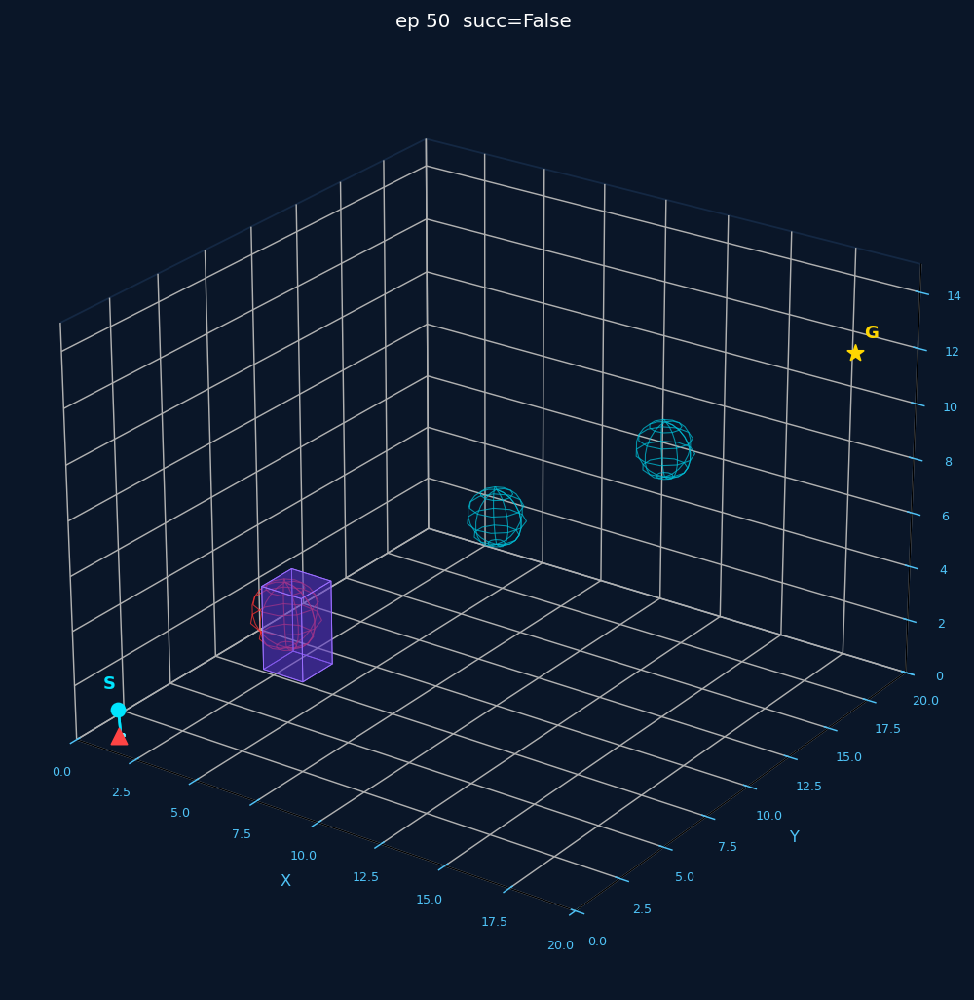

  3-D viewer → models_uav/viewer_ep50.html


  ep    52/100 | stg 0 | r     20.7 | succ  50.0% | coll   0.0% | CL 0.4632 | AL -36.0878 | noise 0.3500 | 7.4min

  *** CURRICULUM ADVANCE → Stage 1 ***

  ep    54/100 | stg 1 | r    -44.6 | succ   0.0% | coll   0.0% | CL 0.5419 | AL -35.2380 | noise 0.3500 | 7.5min
  ep    56/100 | stg 1 | r     46.5 | succ  50.0% | coll   0.0% | CL 0.5447 | AL -34.1836 | noise 0.3500 | 7.6min
  ep    58/100 | stg 1 | r   -103.6 | succ   0.0% | coll   0.0% | CL 0.5185 | AL -32.9602 | noise 0.3500 | 8.6min
  ep    60/100 | stg 1 | r    -58.9 | succ   0.0% | coll   0.0% | CL 0.4796 | AL -31.5370 | noise 0.3500 | 8.7min
  ep    62/100 | stg 1 | r   -134.4 | succ   0.0% | coll   0.0% | CL 0.5514 | AL -31.3261 | noise 0.3500 | 8.9min
  ep    64/100 | stg 1 | r    -88.1 | succ   0.0% | coll   0.0% | CL 0.5578 | AL -31.2945 | noise 0.3500 | 8.9min
  ep    66/100 | stg 1 | r   -134.7 | succ   0.0% | coll   0.0% | CL 0.6710 | AL -30.7165 | noise 0.3500 | 9.2min
  ep    68/100 | stg 1 | r    133.8 | succ 100.

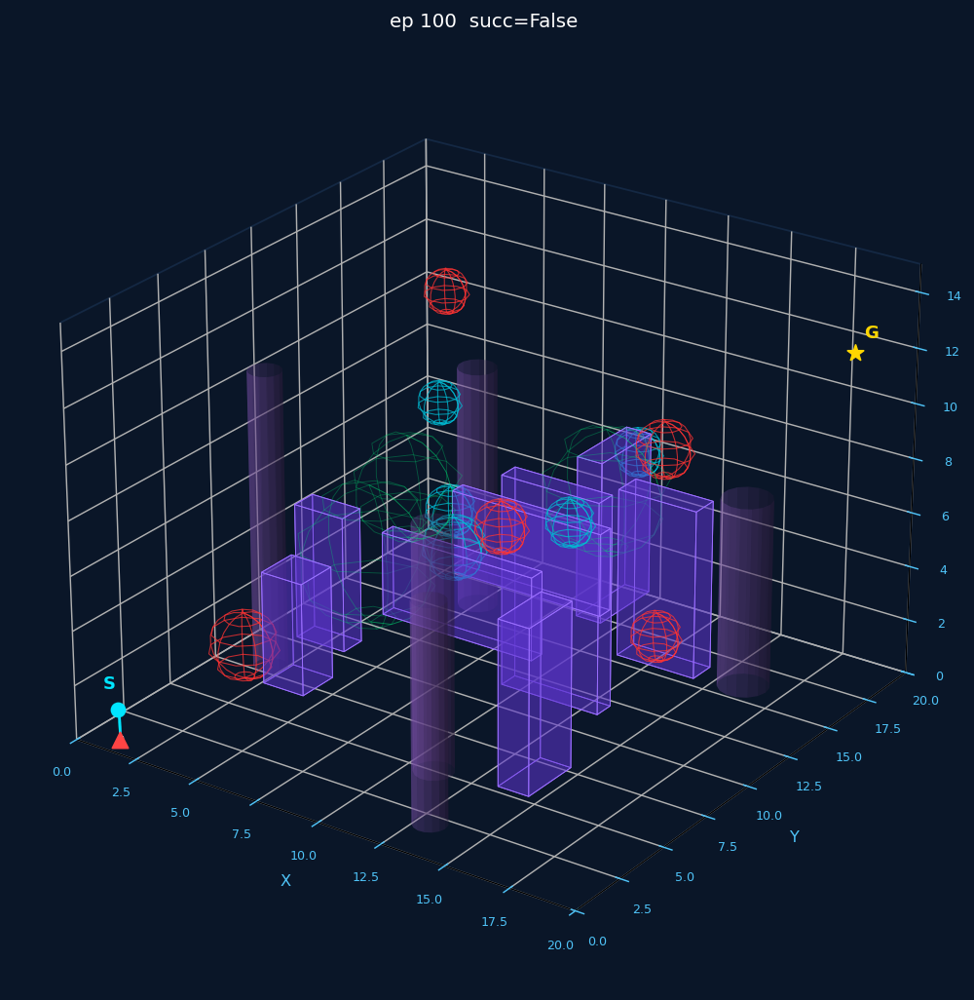

  3-D viewer → models_uav/viewer_ep100.html


  [ckpt ep=100] success=False  dist=27.09m  → models_uav/test_traj_ep100.npy

  Training done  (12.0 min)  total_env_steps≈52,230
  Final model → models_uav/arc_multi_final.pt

  Final test: success=False  dist=27.53m
  Training curves → models_uav/training_curves.png


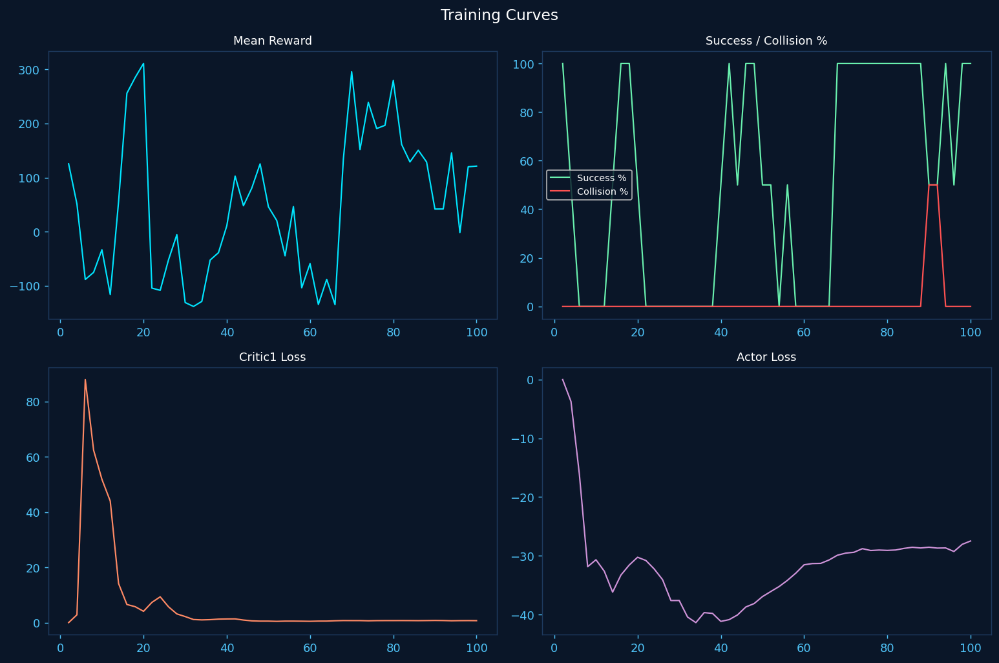

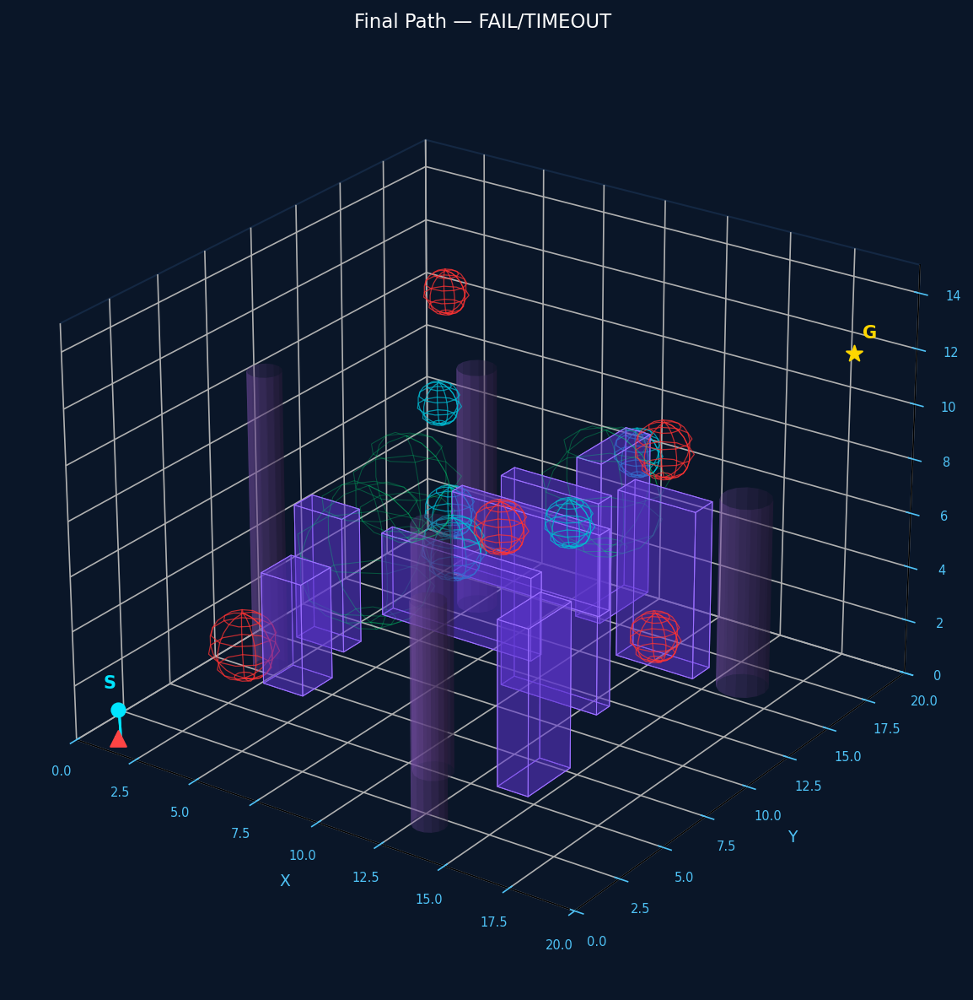

  3-D viewer → models_uav/final_trajectory_viewer.html


  GIF saved → models_uav/final_trajectory.gif


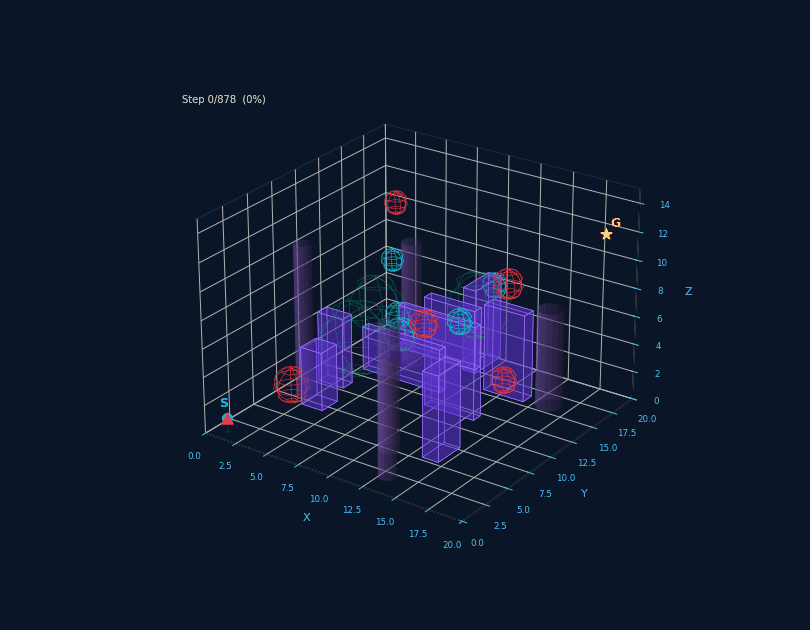


  TIP: regenerate viewer from any saved trajectory:
       generate_viewer_from_npy('models_uav/test_traj_ep<N>.npy')


In [10]:
trainer = run_training()


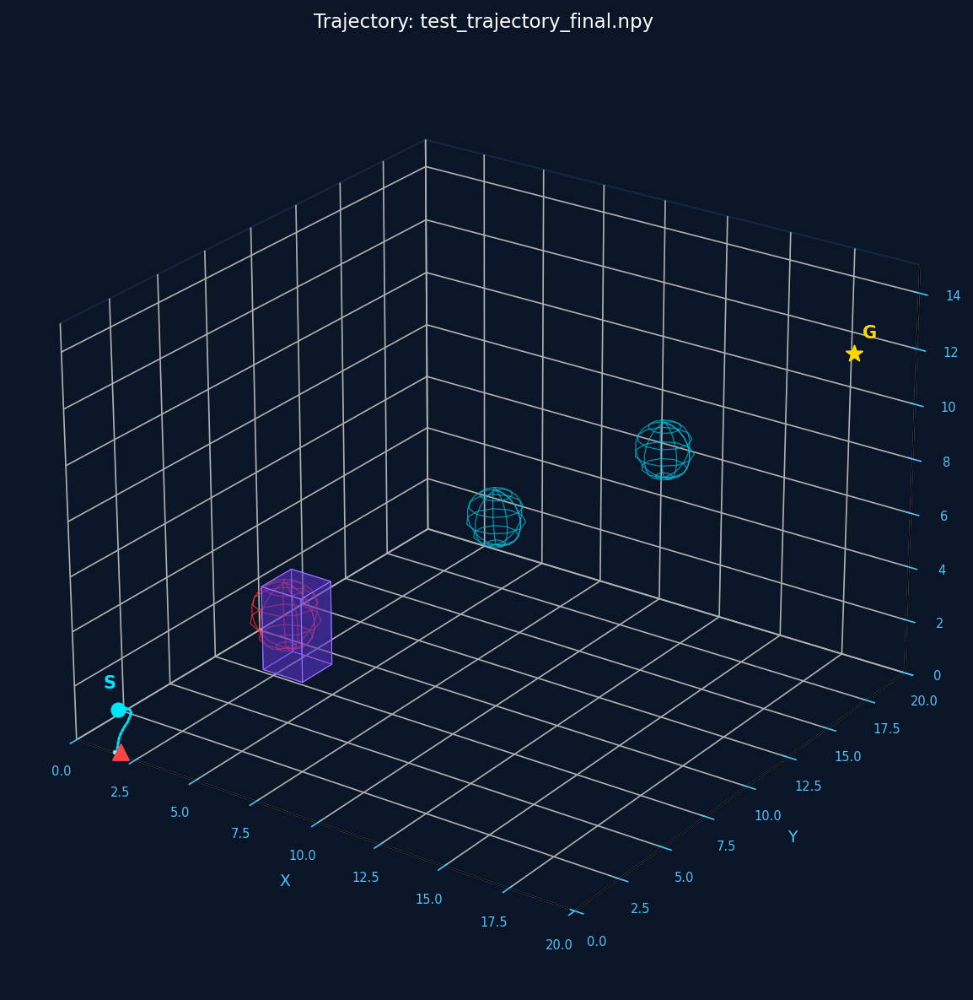

  3-D viewer → /kaggle/working/models_uav/test_trajectory_final_viewer.html


  GIF saved → /kaggle/working/models_uav/test_trajectory_final_vis.gif


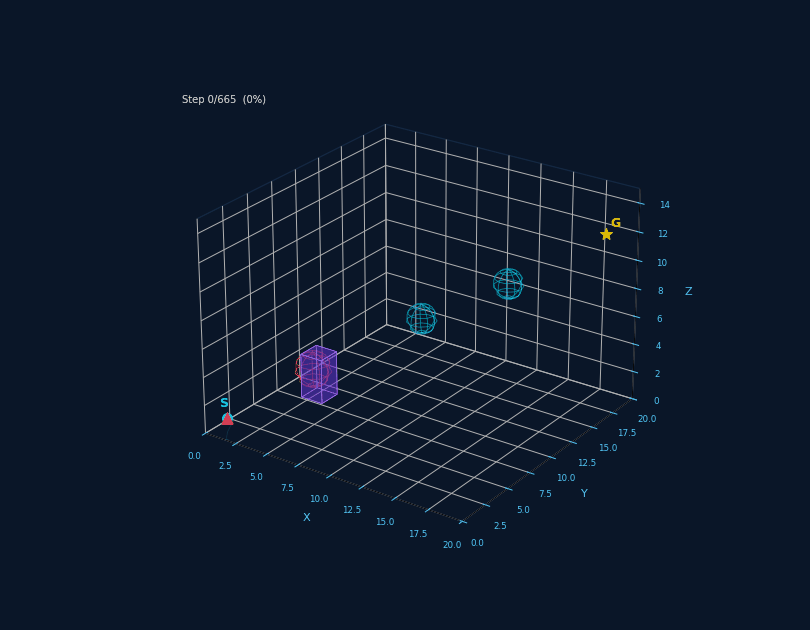

  Done. Files saved with prefix: /kaggle/working/models_uav/test_trajectory_final


In [4]:
run_visualise("/kaggle/working/models_uav/test_trajectory_final.npy",0)

In [16]:
# ── Run settings ──────────────────────────────────────────────────────────────
NUM_EPISODES      = 500       # total training episodes this session
N_ENVS            = 10        # parallel UAVs (lower to 2 if GPU OOM)
SEED              = 42
RESUME_PATH       = "/kaggle/working/models_uav/arc_multi_best.pt"        # path to .pt checkpoint, or "" for fresh training
SAVE_DIR          = "models_uav"
VISUALIZE_EVERY_N = 50       # save PNG+HTML viewer every N episodes (0 = off)
MAKE_GIF          = True
GIF_FPS           = 18
GIF_TAIL          = 30
TEST_EPISODES     = 10

# ── Stage selector ────────────────────────────────────────────────────────────
# Set which curriculum stage to START training at (0, 1, or 2).
# Stage 0 = easy (4 obstacles, near-goal starts)  ← always start here from scratch
# Stage 1 = medium (15 obstacles)
# Stage 2 = hard (23 obstacles + decorative swirls)
# The trainer auto-advances when success rate thresholds are hit.
# If resuming a checkpoint already trained past stage 0, set this to match.
START_STAGE = 2


TRAIN3D_CONFIG = {
    "num_episodes":           NUM_EPISODES,
    "batch_size":              256,
    "memory_capacity":       100_000,  # smaller fills faster → more diverse early batches
    "learning_rate":           1e-4,
    "gamma":                   0.98,   # shorter horizon: easier early credit assignment
    "tau":                     0.005,
    "exploration_noise":       0.35,
    # CRITICAL FIX: decay applied per EPISODE not per step
    # 0.992^200 ≈ 0.20, so noise goes 0.35 → 0.08 over ~200 episodes
    "noise_decay":             0.992,
    "noise_floor":             0.08,
    "warmup_steps":            500,    # stage-0 episodes are short, fills fast
    "policy_delay":            2,
    "target_noise":            0.1,
    "target_noise_clip":       0.3,
    "curriculum_thresholds":   [0.50, 0.65],
    "curriculum_window":       20,     # rolling window for success rate check
    "her_k":                   6,
    "n_envs":                  N_ENVS,
    "updates_per_episode":     4,
    "start_stage":             START_STAGE,
}


  Multi-UAV TD3-ARC  |  device=cuda
  GPU: Tesla T4
  Resumed from: /kaggle/working/models_uav/arc_multi_best.pt
  n_envs=10  obs=18  act=3  start_stage=2

  Training 500 eps × 10 UAVs  (warmup=500  noise=0.35→0.08  HER k=6)
  Stage-0 starts sampled within 6 m of goal — expands with curriculum.

  ep    12/500 | stg 2 | r     73.7 | succ  58.3% | coll  41.7% | CL 7.3032 | AL -22.6627 | noise 0.3500 | 0.5min
  ep    24/500 | stg 2 | r     33.3 | succ  75.0% | coll  25.0% | CL 0.6272 | AL -22.1669 | noise 0.3500 | 2.0min
  ep    36/500 | stg 2 | r     62.7 | succ  66.7% | coll   8.3% | CL 0.2889 | AL -23.4439 | noise 0.3500 | 2.6min
  ep    48/500 | stg 2 | r     96.3 | succ  83.3% | coll   8.3% | CL 0.3437 | AL -25.5474 | noise 0.3500 | 2.9min
  ep    60/500 | stg 2 | r    114.8 | succ  83.3% | coll  16.7% | CL 0.3177 | AL -24.9934 | noise 0.3500 | 3.3min
  ep    72/500 | stg 2 | r    153.5 | succ 100.0% | coll   0.0% | CL 0.2950 | AL -23.8940 | noise 0.3500 | 3.8min
  ep    84/500 | s

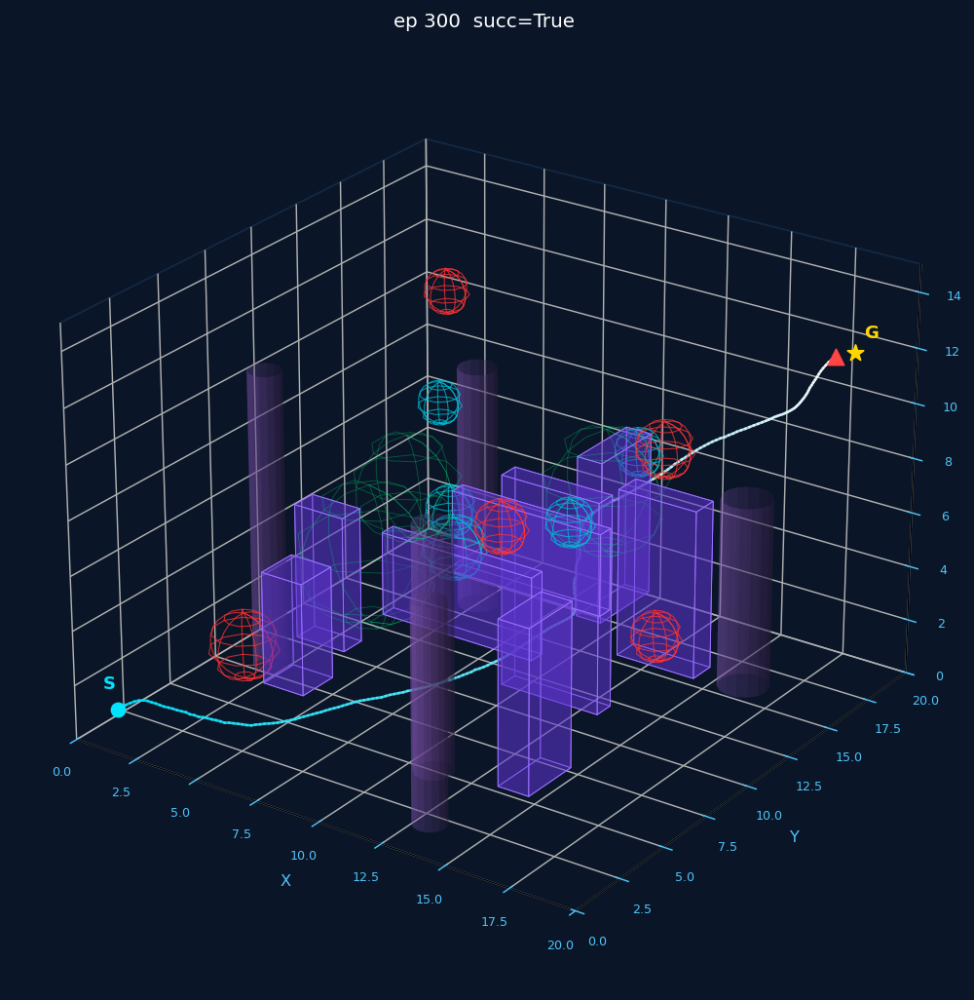

  3-D viewer → models_uav/viewer_ep300.html


  [ckpt ep=300] success=True  dist=0.79m  → models_uav/test_traj_ep300.npy
  [ckpt ep=300] success=True  dist=0.75m  → models_uav/test_traj_ep300.npy
  [ckpt ep=300] success=True  dist=0.76m  → models_uav/test_traj_ep300.npy
  [ckpt ep=300] success=True  dist=0.69m  → models_uav/test_traj_ep300.npy
  [ckpt ep=300] success=True  dist=0.76m  → models_uav/test_traj_ep300.npy
  [ckpt ep=300] success=True  dist=0.71m  → models_uav/test_traj_ep300.npy
  [ckpt ep=300] success=True  dist=0.67m  → models_uav/test_traj_ep300.npy
  [ckpt ep=300] success=True  dist=0.72m  → models_uav/test_traj_ep300.npy
  [ckpt ep=300] success=True  dist=0.68m  → models_uav/test_traj_ep300.npy
  [ckpt ep=300] success=True  dist=0.69m  → models_uav/test_traj_ep300.npy
  [ckpt ep=300] success=True  dist=0.77m  → models_uav/test_traj_ep300.npy
  [ckpt ep=300] success=True  dist=0.70m  → models_uav/test_traj_ep300.npy
  [ckpt ep=300] success=True  dist=0.76m  → models_uav/test_traj_ep300.npy
  [ckpt ep=300] success=T

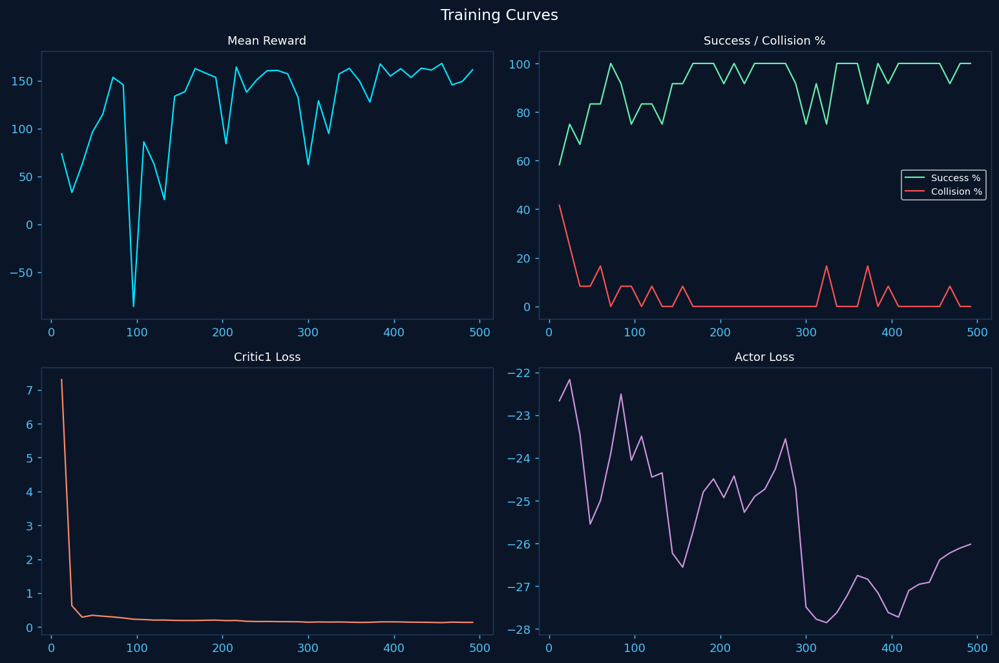

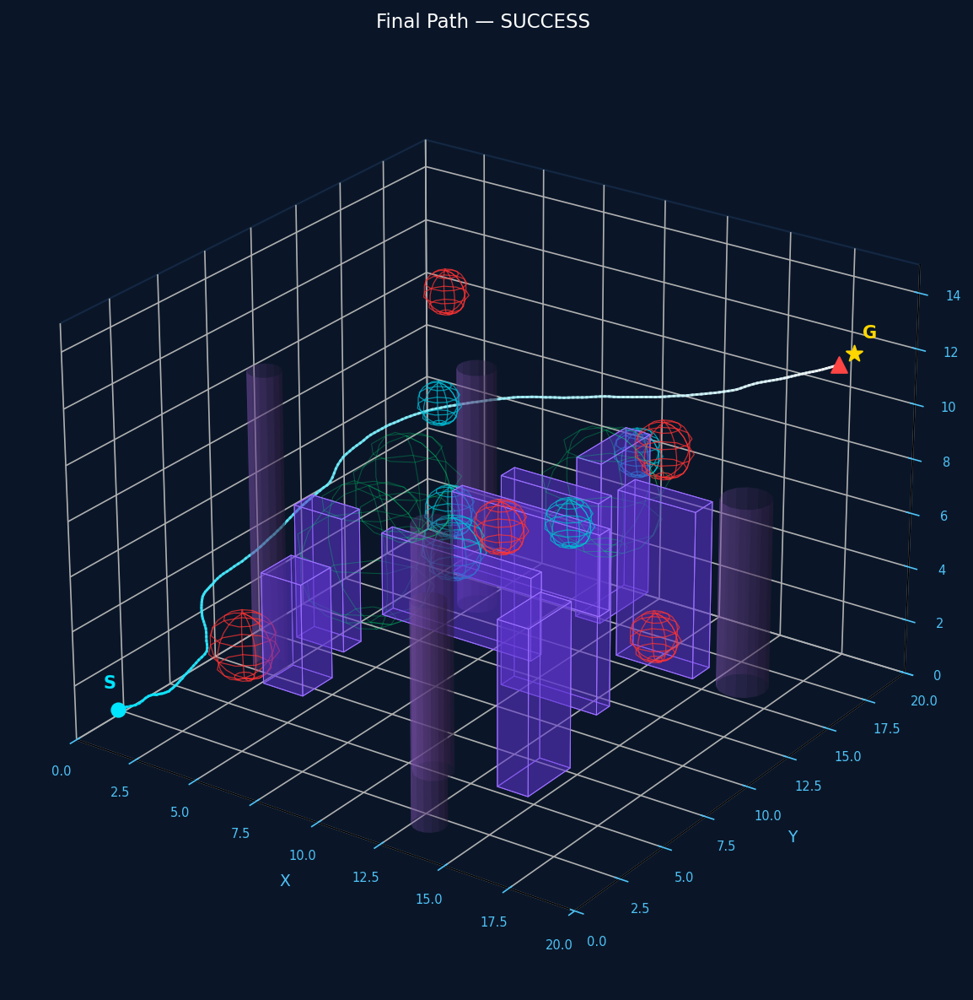

  3-D viewer → models_uav/final_trajectory_viewer.html


  GIF saved → models_uav/final_trajectory.gif


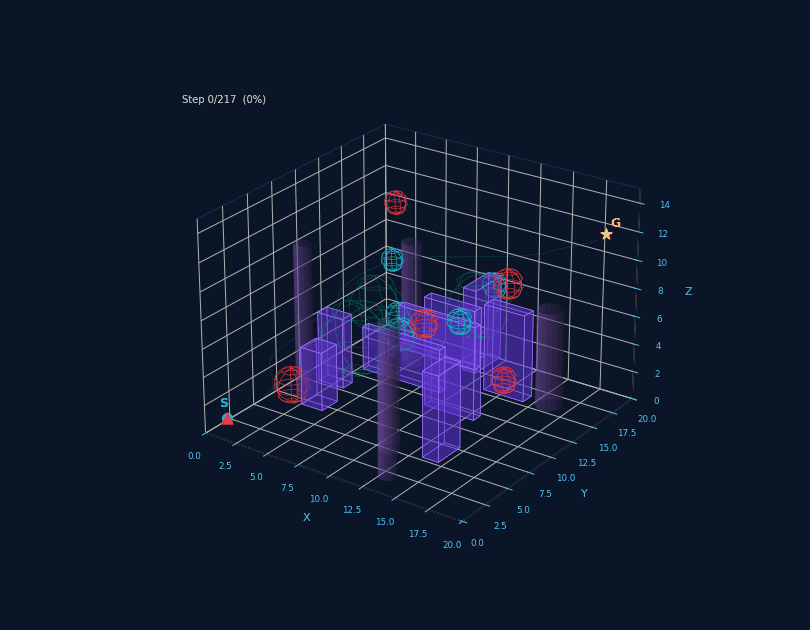


  TIP: regenerate viewer from any saved trajectory:
       generate_viewer_from_npy('models_uav/test_traj_ep<N>.npy')


In [17]:
trainer = run_training()



  Multi-UAV TD3-ARC  |  device=cuda
  GPU: Tesla T4
  Resumed from: /kaggle/working/models_uav/arc_multi_best.pt
  n_envs=1  obs=18  act=3  start_stage=2

  Loaded: /kaggle/working/models_uav/arc_multi_ep500.pt

  Testing 10 eps  fixed start→goal

  ep   1: success=True  dist=0.68m  steps=219  path=32.94m
  ep   2: success=True  dist=0.75m  steps=240  path=35.91m
  ep   3: success=True  dist=0.68m  steps=221  path=33.12m
  ep   4: success=True  dist=0.72m  steps=220  path=32.88m
  ep   5: success=True  dist=0.71m  steps=218  path=32.71m
  ep   6: success=True  dist=0.69m  steps=218  path=32.70m
  ep   7: success=True  dist=0.77m  steps=218  path=32.61m
  ep   8: success=True  dist=0.78m  steps=217  path=32.65m
  ep   9: success=True  dist=0.80m  steps=217  path=32.65m
  ep  10: success=True  dist=0.72m  steps=221  path=33.14m

  Success: 100.0%  Avg path: 33.13m  Avg steps: 221


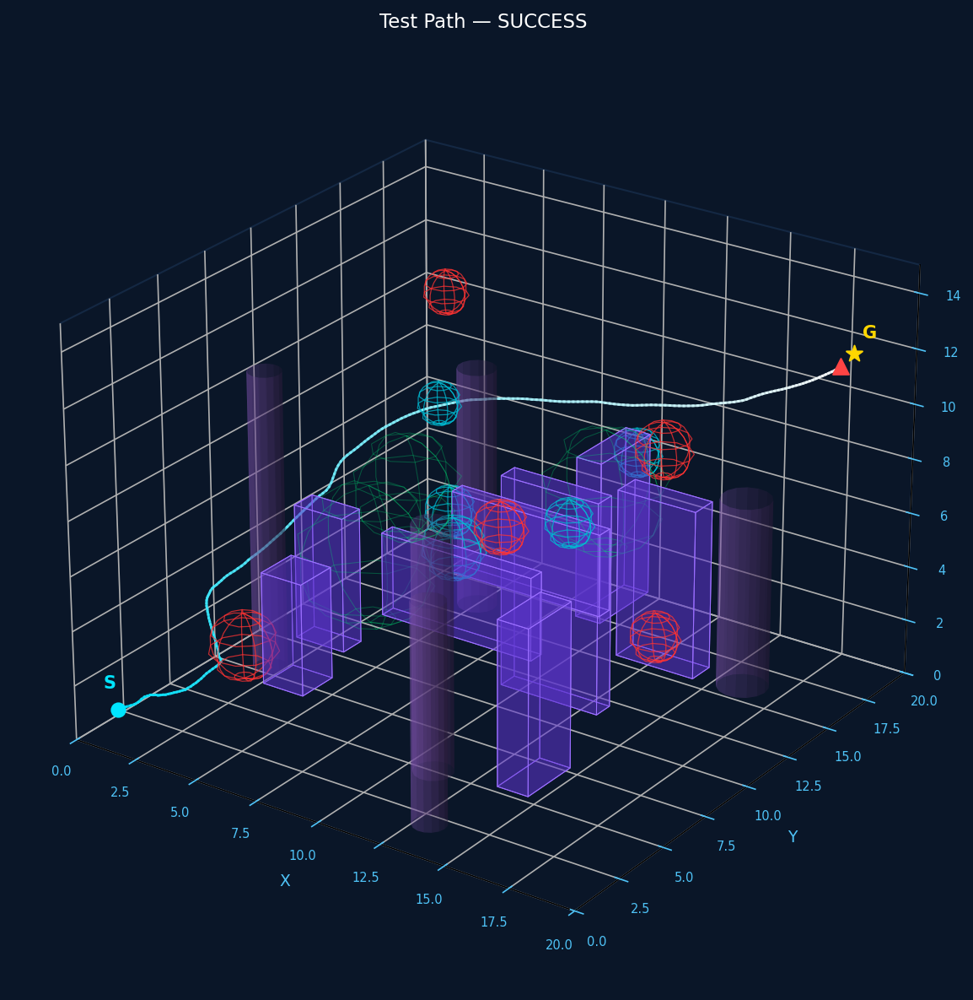

  3-D viewer → models_uav/test_trajectory_viewer.html


  GIF saved → models_uav/test_trajectory.gif


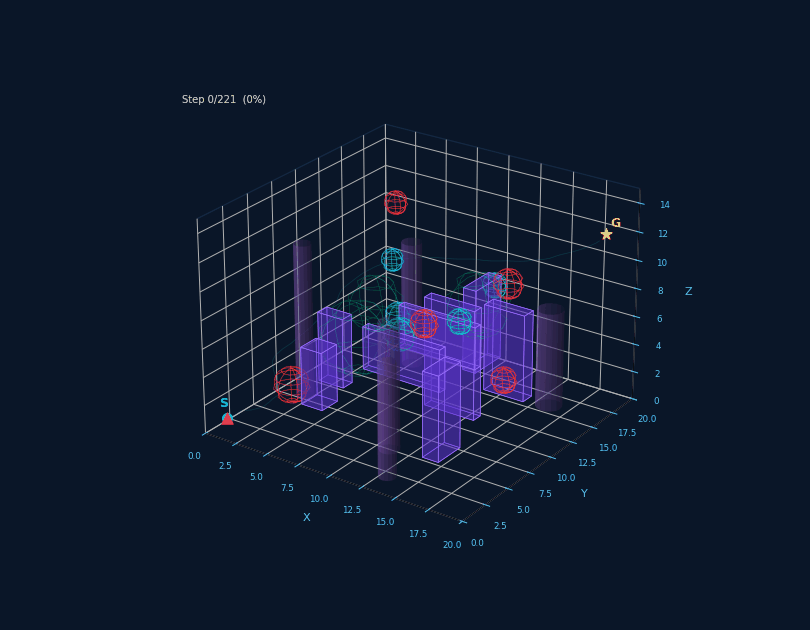

In [24]:
traj, info = run_test("/kaggle/working/models_uav/arc_multi_ep500.pt")

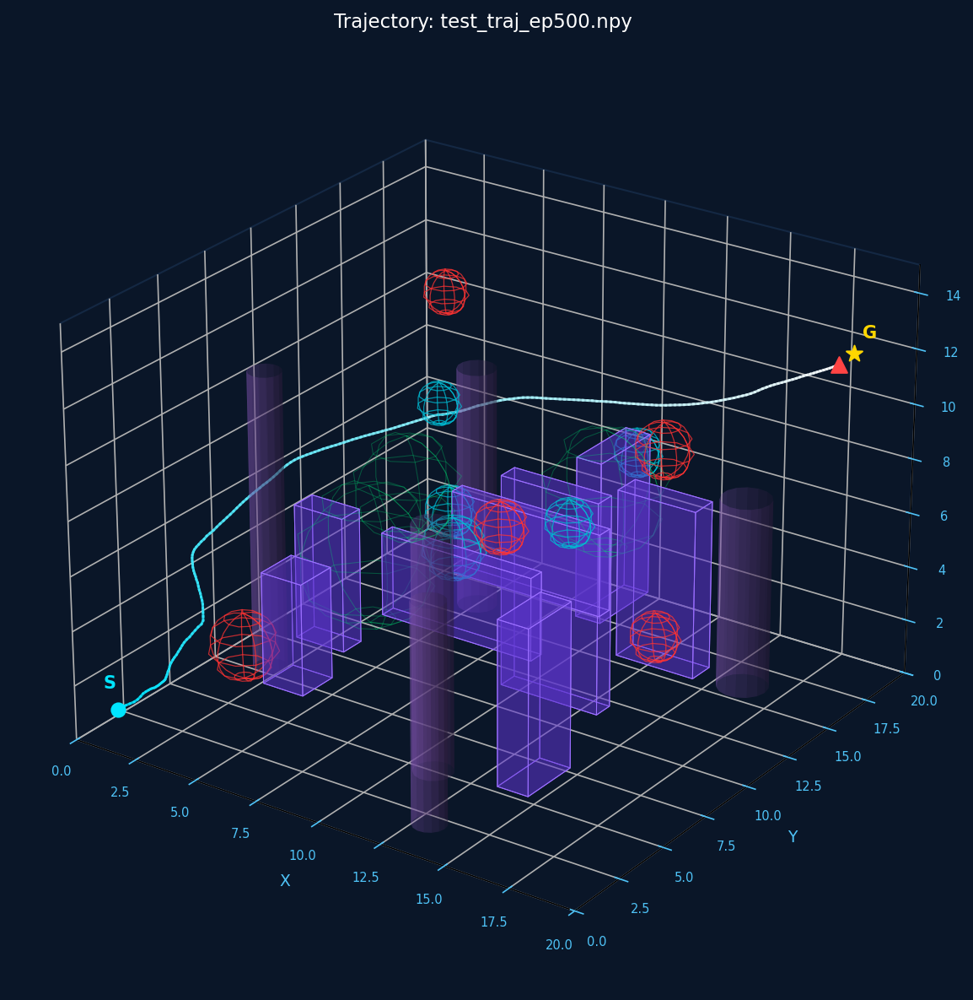

  3-D viewer → /kaggle/working/models_uav/test_traj_ep500_viewer.html


  GIF saved → /kaggle/working/models_uav/test_traj_ep500_vis.gif


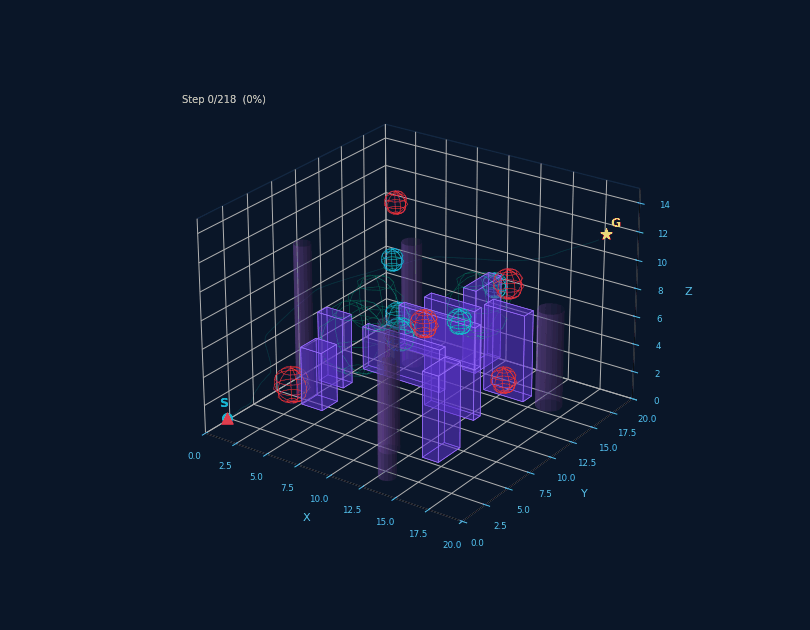

  Done. Files saved with prefix: /kaggle/working/models_uav/test_traj_ep500


In [27]:
run_visualise("/kaggle/working/models_uav/test_traj_ep500.npy")